## Learning objectives of this notebook

1. Load multiple DARTS simulations using pandas
2. Compile data for all simulations in pandas
3. Plot data using seaborn
4. Pre-treat data for economic analysis
5. Compute LCOH


In [1]:
pip install CoolProp

Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import os
import matplotlib.pyplot as plt
from CoolProp.CoolProp import PropsSI

In [3]:
# Load our simulation output data
# get all Excel files
#flist = [os.path.join(dp, n) for dp, dn, fn in os.walk(os.getcwd())
#            for n in fn
#            if n.endswith('.xlsx')
#            and os.path.isfile(os.path.join(dp, n))]
flist = [os.path.join(os.getcwd(), 'well_time_data.xlsx')]

In [4]:
flist


['c:\\Users\\Acer\\Documents\\GEIP\\Economic_Geip\\well_time_data.xlsx']

In [5]:
# load example simulation data
data = pd.read_excel(flist[0])
data.head(10)

,time,well_I_BHP,well_I_BHT,well_P_BHP,well_P_BHT,well_I_perf_0_molar_rate_wat,well_I_perf_0_molar_rate_gas,well_I_perf_1_molar_rate_wat,well_I_perf_1_molar_rate_gas,well_I_perf_2_molar_rate_wat,...,well_P_perf_0_advective_heat_rate_wat,well_P_perf_0_advective_heat_rate_gas,well_I_advective_heat_rate_wat_by_sum_perfs,well_I_advective_heat_rate_gas_by_sum_perfs,well_P_advective_heat_rate_wat_by_sum_perfs,well_P_advective_heat_rate_gas_by_sum_perfs,well_I_advective_heat_rate_wat_at_wh,well_I_advective_heat_rate_gas_at_wh,well_P_advective_heat_rate_wat_at_wh,well_P_advective_heat_rate_gas_at_wh
0,0.000100,198.545650,300,152.429532,349.842250,-94967.280216,0,-0.001061,0,-76782.034077,...,-1.510732e+09,0,2.874551e+08,0,-1.510732e+09,0,2.905993e+08,0,-1.508982e+09,0
1,0.000220,198.883364,300,147.856051,349.866548,-56555.303868,0,-0.000693,0,-29541.698395,...,-1.509820e+09,0,2.921084e+08,0,-1.509820e+09,0,2.906015e+08,0,-1.509491e+09,0
2,0.000364,199.086818,300,145.586164,349.854881,-35314.440664,0,-0.000447,0,-4239.503053,...,-1.509346e+09,0,2.914437e+08,0,-1.509346e+09,0,2.906029e+08,0,-1.509163e+09,0
3,0.000537,199.229250,300,144.268396,349.845821,-20646.396809,0,-0.000259,0,12829.678054,...,-1.509071e+09,0,2.867252e+08,0,-1.509071e+09,0,2.906038e+08,0,-1.508917e+09,0
4,0.000744,199.339701,300,143.457974,349.839987,-9044.357237,0,-0.000105,0,26249.246757,...,-1.508902e+09,0,2.905534e+08,0,-1.508902e+09,0,2.906045e+08,0,-1.508759e+09,0
5,0.000993,199.430691,300,142.969222,349.836439,945.260733,0,0.000026,0,37965.349736,...,-1.508801e+09,0,2.904716e+08,0,-1.508801e+09,0,2.906051e+08,0,-1.508663e+09,0
6,0.001292,199.508326,300,142.697775,349.834488,10094.722957,0,0.000139,0,48985.362681,...,-1.508745e+09,0,2.906034e+08,0,-1.508745e+09,0,2.906056e+08,0,-1.508610e+09,0
7,0.001650,199.575923,300,142.571990,349.833623,18869.725130,0,0.000241,0,59854.969977,...,-1.508720e+09,0,2.906067e+08,0,-1.508720e+09,0,2.906061e+08,0,-1.508587e+09,0
8,0.002080,199.635386,300,142.539864,349.833467,27549.518910,0,0.000335,0,70844.575012,...,-1.508715e+09,0,2.906070e+08,0,-1.508715e+09,0,2.906065e+08,0,-1.508583e+09,0
9,0.002596,199.687834,300,142.564848,349.833752,36284.426298,0,0.000425,0,82061.292175,...,-1.508722e+09,0,2.906072e+08,0,-1.508722e+09,0,2.906068e+08,0,-1.508590e+09,0


In [6]:
data.columns.tolist()

['time',
 'well_I_BHP',
 'well_I_BHT',
 'well_P_BHP',
 'well_P_BHT',
 'well_I_perf_0_molar_rate_wat',
 'well_I_perf_0_molar_rate_gas',
 'well_I_perf_1_molar_rate_wat',
 'well_I_perf_1_molar_rate_gas',
 'well_I_perf_2_molar_rate_wat',
 'well_I_perf_2_molar_rate_gas',
 'well_I_perf_3_molar_rate_wat',
 'well_I_perf_3_molar_rate_gas',
 'well_I_perf_4_molar_rate_wat',
 'well_I_perf_4_molar_rate_gas',
 'well_I_perf_5_molar_rate_wat',
 'well_I_perf_5_molar_rate_gas',
 'well_I_perf_6_molar_rate_wat',
 'well_I_perf_6_molar_rate_gas',
 'well_I_perf_7_molar_rate_wat',
 'well_I_perf_7_molar_rate_gas',
 'well_I_perf_8_molar_rate_wat',
 'well_I_perf_8_molar_rate_gas',
 'well_I_perf_9_molar_rate_wat',
 'well_I_perf_9_molar_rate_gas',
 'well_I_perf_10_molar_rate_wat',
 'well_I_perf_10_molar_rate_gas',
 'well_I_perf_11_molar_rate_wat',
 'well_I_perf_11_molar_rate_gas',
 'well_I_perf_12_molar_rate_wat',
 'well_I_perf_12_molar_rate_gas',
 'well_I_perf_13_molar_rate_wat',
 'well_I_perf_13_molar_rate_gas',

In [7]:
dfs = []
for file in flist:
    df = pd.read_excel(file)
    df['Simulation'] = file.split(os.sep)[-1].split('.xlsx')[0]
    dfs.append(df)


C:\Users\Acer\AppData\Local\Temp\ipykernel_5832\563946962.py:4: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['Simulation'] = file.split(os.sep)[-1].split('.xlsx')[0]


In [8]:
# compile single dataframe
data = pd.concat(dfs)

In [9]:
data.head(20)

,time,well_I_BHP,well_I_BHT,well_P_BHP,well_P_BHT,well_I_perf_0_molar_rate_wat,well_I_perf_0_molar_rate_gas,well_I_perf_1_molar_rate_wat,well_I_perf_1_molar_rate_gas,well_I_perf_2_molar_rate_wat,...,well_P_perf_0_advective_heat_rate_gas,well_I_advective_heat_rate_wat_by_sum_perfs,well_I_advective_heat_rate_gas_by_sum_perfs,well_P_advective_heat_rate_wat_by_sum_perfs,well_P_advective_heat_rate_gas_by_sum_perfs,well_I_advective_heat_rate_wat_at_wh,well_I_advective_heat_rate_gas_at_wh,well_P_advective_heat_rate_wat_at_wh,well_P_advective_heat_rate_gas_at_wh,Simulation
0,0.000100,198.545650,300,152.429532,349.842250,-94967.280216,0,-0.001061,0,-76782.034077,...,0,2.874551e+08,0,-1.510732e+09,0,2.905993e+08,0,-1.508982e+09,0,well_time_data
1,0.000220,198.883364,300,147.856051,349.866548,-56555.303868,0,-0.000693,0,-29541.698395,...,0,2.921084e+08,0,-1.509820e+09,0,2.906015e+08,0,-1.509491e+09,0,well_time_data
2,0.000364,199.086818,300,145.586164,349.854881,-35314.440664,0,-0.000447,0,-4239.503053,...,0,2.914437e+08,0,-1.509346e+09,0,2.906029e+08,0,-1.509163e+09,0,well_time_data
3,0.000537,199.229250,300,144.268396,349.845821,-20646.396809,0,-0.000259,0,12829.678054,...,0,2.867252e+08,0,-1.509071e+09,0,2.906038e+08,0,-1.508917e+09,0,well_time_data
4,0.000744,199.339701,300,143.457974,349.839987,-9044.357237,0,-0.000105,0,26249.246757,...,0,2.905534e+08,0,-1.508902e+09,0,2.906045e+08,0,-1.508759e+09,0,well_time_data
5,0.000993,199.430691,300,142.969222,349.836439,945.260733,0,0.000026,0,37965.349736,...,0,2.904716e+08,0,-1.508801e+09,0,2.906051e+08,0,-1.508663e+09,0,well_time_data
6,0.001292,199.508326,300,142.697775,349.834488,10094.722957,0,0.000139,0,48985.362681,...,0,2.906034e+08,0,-1.508745e+09,0,2.906056e+08,0,-1.508610e+09,0,well_time_data
7,0.001650,199.575923,300,142.571990,349.833623,18869.725130,0,0.000241,0,59854.969977,...,0,2.906067e+08,0,-1.508720e+09,0,2.906061e+08,0,-1.508587e+09,0,well_time_data
8,0.002080,199.635386,300,142.539864,349.833467,27549.518910,0,0.000335,0,70844.575012,...,0,2.906070e+08,0,-1.508715e+09,0,2.906065e+08,0,-1.508583e+09,0,well_time_data
9,0.002596,199.687834,300,142.564848,349.833752,36284.426298,0,0.000425,0,82061.292175,...,0,2.906072e+08,0,-1.508722e+09,0,2.906068e+08,0,-1.508590e+09,0,well_time_data


In [10]:
# reset index to avoid duplicate entries
data.reset_index(drop=True, inplace=True)

In [11]:
# check that we have the simulations as expected
data['Simulation'].unique()

<ArrowStringArray>
['well_time_data']
Length: 1, dtype: str

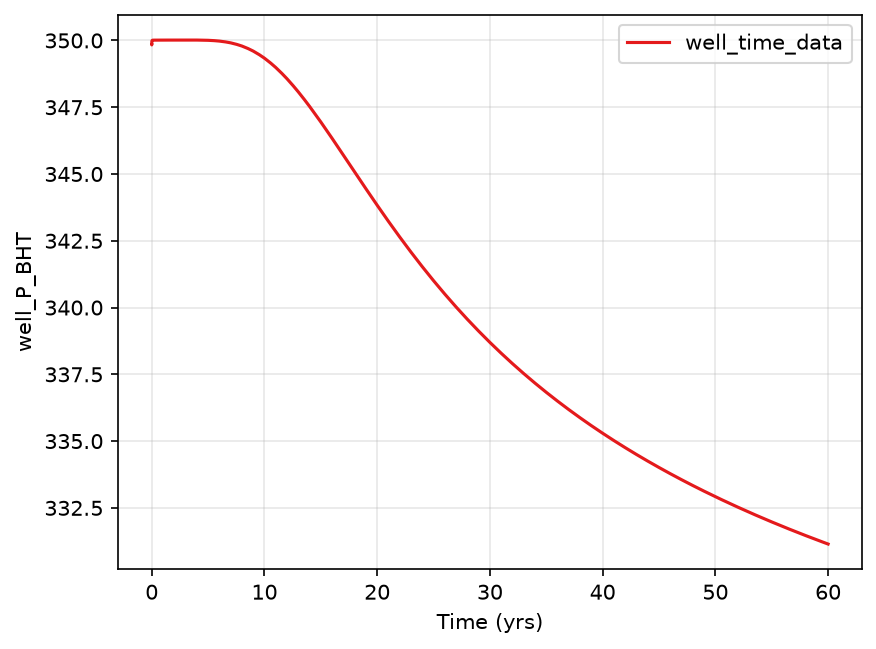

In [13]:
data['Time (yrs)'] = data['time'] / 365.25
fig, ax = plt.subplots(1,1, dpi=150)
sns.lineplot(x='Time (yrs)', y='well_P_BHT', 
             hue='Simulation',  
             style='Simulation',
             data=data, 
             palette='Set1', 
             ax=ax)
#ax.axhline(345, linestyle=':', label='thermal breakthrough', color='k')
ax.legend()
ax.grid(alpha=0.3)

In [14]:
# load example simulation data
data = pd.read_excel(flist[0])
data.head(10)

,time,well_I_BHP,well_I_BHT,well_P_BHP,well_P_BHT,well_I_perf_0_molar_rate_wat,well_I_perf_0_molar_rate_gas,well_I_perf_1_molar_rate_wat,well_I_perf_1_molar_rate_gas,well_I_perf_2_molar_rate_wat,...,well_P_perf_0_advective_heat_rate_wat,well_P_perf_0_advective_heat_rate_gas,well_I_advective_heat_rate_wat_by_sum_perfs,well_I_advective_heat_rate_gas_by_sum_perfs,well_P_advective_heat_rate_wat_by_sum_perfs,well_P_advective_heat_rate_gas_by_sum_perfs,well_I_advective_heat_rate_wat_at_wh,well_I_advective_heat_rate_gas_at_wh,well_P_advective_heat_rate_wat_at_wh,well_P_advective_heat_rate_gas_at_wh
0,0.000100,198.545650,300,152.429532,349.842250,-94967.280216,0,-0.001061,0,-76782.034077,...,-1.510732e+09,0,2.874551e+08,0,-1.510732e+09,0,2.905993e+08,0,-1.508982e+09,0
1,0.000220,198.883364,300,147.856051,349.866548,-56555.303868,0,-0.000693,0,-29541.698395,...,-1.509820e+09,0,2.921084e+08,0,-1.509820e+09,0,2.906015e+08,0,-1.509491e+09,0
2,0.000364,199.086818,300,145.586164,349.854881,-35314.440664,0,-0.000447,0,-4239.503053,...,-1.509346e+09,0,2.914437e+08,0,-1.509346e+09,0,2.906029e+08,0,-1.509163e+09,0
3,0.000537,199.229250,300,144.268396,349.845821,-20646.396809,0,-0.000259,0,12829.678054,...,-1.509071e+09,0,2.867252e+08,0,-1.509071e+09,0,2.906038e+08,0,-1.508917e+09,0
4,0.000744,199.339701,300,143.457974,349.839987,-9044.357237,0,-0.000105,0,26249.246757,...,-1.508902e+09,0,2.905534e+08,0,-1.508902e+09,0,2.906045e+08,0,-1.508759e+09,0
5,0.000993,199.430691,300,142.969222,349.836439,945.260733,0,0.000026,0,37965.349736,...,-1.508801e+09,0,2.904716e+08,0,-1.508801e+09,0,2.906051e+08,0,-1.508663e+09,0
6,0.001292,199.508326,300,142.697775,349.834488,10094.722957,0,0.000139,0,48985.362681,...,-1.508745e+09,0,2.906034e+08,0,-1.508745e+09,0,2.906056e+08,0,-1.508610e+09,0
7,0.001650,199.575923,300,142.571990,349.833623,18869.725130,0,0.000241,0,59854.969977,...,-1.508720e+09,0,2.906067e+08,0,-1.508720e+09,0,2.906061e+08,0,-1.508587e+09,0
8,0.002080,199.635386,300,142.539864,349.833467,27549.518910,0,0.000335,0,70844.575012,...,-1.508715e+09,0,2.906070e+08,0,-1.508715e+09,0,2.906065e+08,0,-1.508583e+09,0
9,0.002596,199.687834,300,142.564848,349.833752,36284.426298,0,0.000425,0,82061.292175,...,-1.508722e+09,0,2.906072e+08,0,-1.508722e+09,0,2.906068e+08,0,-1.508590e+09,0


In [15]:
# Check available columns in the data
data.columns.tolist()

['time',
 'well_I_BHP',
 'well_I_BHT',
 'well_P_BHP',
 'well_P_BHT',
 'well_I_perf_0_molar_rate_wat',
 'well_I_perf_0_molar_rate_gas',
 'well_I_perf_1_molar_rate_wat',
 'well_I_perf_1_molar_rate_gas',
 'well_I_perf_2_molar_rate_wat',
 'well_I_perf_2_molar_rate_gas',
 'well_I_perf_3_molar_rate_wat',
 'well_I_perf_3_molar_rate_gas',
 'well_I_perf_4_molar_rate_wat',
 'well_I_perf_4_molar_rate_gas',
 'well_I_perf_5_molar_rate_wat',
 'well_I_perf_5_molar_rate_gas',
 'well_I_perf_6_molar_rate_wat',
 'well_I_perf_6_molar_rate_gas',
 'well_I_perf_7_molar_rate_wat',
 'well_I_perf_7_molar_rate_gas',
 'well_I_perf_8_molar_rate_wat',
 'well_I_perf_8_molar_rate_gas',
 'well_I_perf_9_molar_rate_wat',
 'well_I_perf_9_molar_rate_gas',
 'well_I_perf_10_molar_rate_wat',
 'well_I_perf_10_molar_rate_gas',
 'well_I_perf_11_molar_rate_wat',
 'well_I_perf_11_molar_rate_gas',
 'well_I_perf_12_molar_rate_wat',
 'well_I_perf_12_molar_rate_gas',
 'well_I_perf_13_molar_rate_wat',
 'well_I_perf_13_molar_rate_gas',

In [16]:
# list the collumn names that should be removed
press_gridcells = data.filter(like='reservoir').columns.tolist()
chem_cols = data.filter(like='Kmol').columns.tolist()

# remove collumns from data
data.drop(columns=press_gridcells + chem_cols, inplace=True)


# add time in years
data['Time (yrs)'] = data['time'] / 365.25

data.columns.tolist()

C:\Users\Acer\AppData\Local\Temp\ipykernel_5832\389435207.py:10: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  data['Time (yrs)'] = data['time'] / 365.25


['time',
 'well_I_BHP',
 'well_I_BHT',
 'well_P_BHP',
 'well_P_BHT',
 'well_I_perf_0_molar_rate_wat',
 'well_I_perf_0_molar_rate_gas',
 'well_I_perf_1_molar_rate_wat',
 'well_I_perf_1_molar_rate_gas',
 'well_I_perf_2_molar_rate_wat',
 'well_I_perf_2_molar_rate_gas',
 'well_I_perf_3_molar_rate_wat',
 'well_I_perf_3_molar_rate_gas',
 'well_I_perf_4_molar_rate_wat',
 'well_I_perf_4_molar_rate_gas',
 'well_I_perf_5_molar_rate_wat',
 'well_I_perf_5_molar_rate_gas',
 'well_I_perf_6_molar_rate_wat',
 'well_I_perf_6_molar_rate_gas',
 'well_I_perf_7_molar_rate_wat',
 'well_I_perf_7_molar_rate_gas',
 'well_I_perf_8_molar_rate_wat',
 'well_I_perf_8_molar_rate_gas',
 'well_I_perf_9_molar_rate_wat',
 'well_I_perf_9_molar_rate_gas',
 'well_I_perf_10_molar_rate_wat',
 'well_I_perf_10_molar_rate_gas',
 'well_I_perf_11_molar_rate_wat',
 'well_I_perf_11_molar_rate_gas',
 'well_I_perf_12_molar_rate_wat',
 'well_I_perf_12_molar_rate_gas',
 'well_I_perf_13_molar_rate_wat',
 'well_I_perf_13_molar_rate_gas',

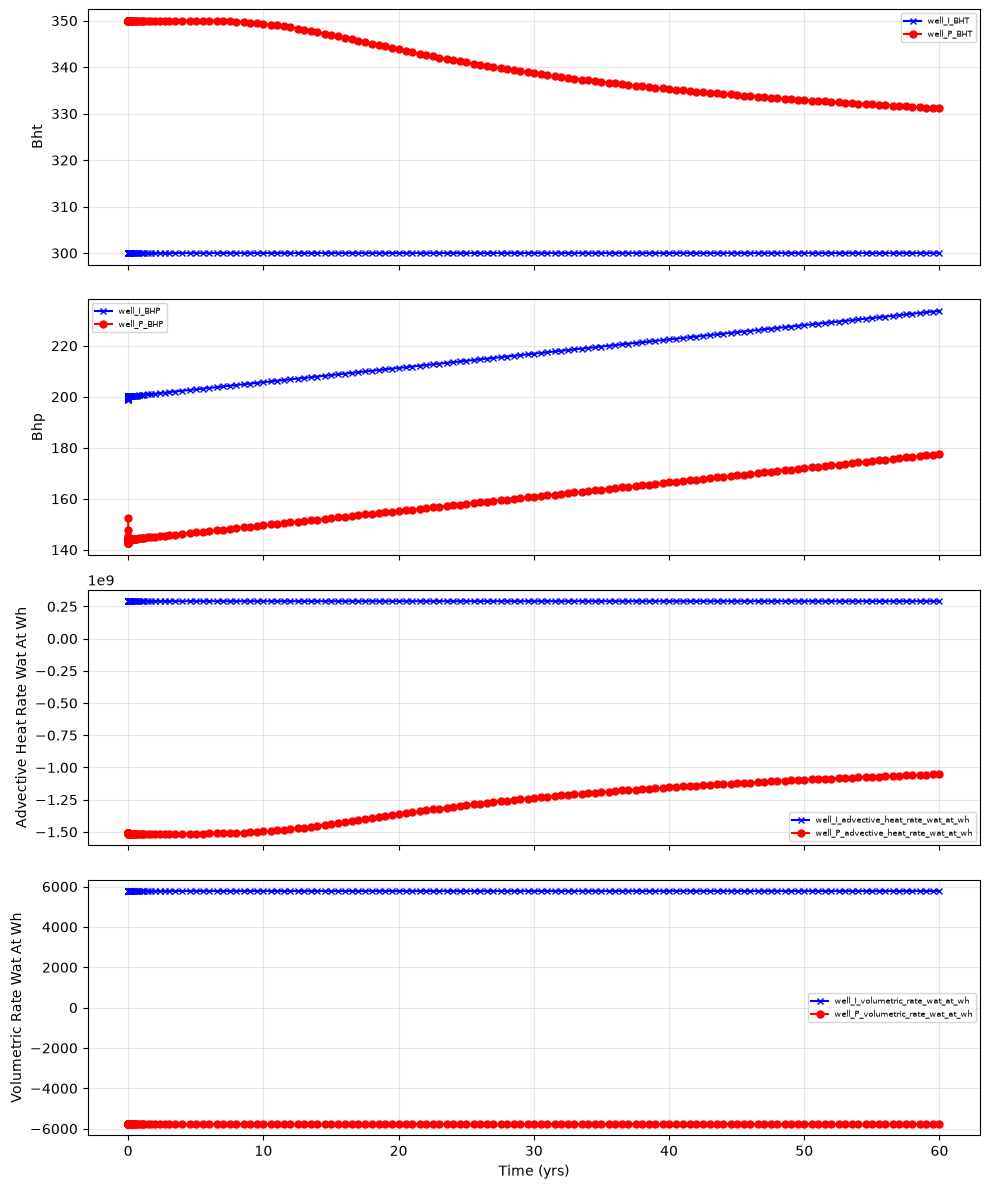

In [17]:
import matplotlib.pyplot as plt

# 1. Create the figure and subplots array (4 plots vertically)
fig, ax_list = plt.subplots(nrows=4, ncols=1, figsize=(10, 12), sharex=True)

# 2. Define keywords
keywords = [
    'BHT', 
    'BHP', 
    'advective_heat_rate_wat_at_wh', 
    'volumetric_rate_wat_at_wh'
]

# 3. Plot loop
for i, key in enumerate(keywords):
    cols = data.filter(like=key).columns.tolist()
    if cols:
        data.plot(
            x='Time (yrs)',
            y=cols,
            ax=ax_list[i],
            linestyle='-',
            style=['x', 'o'],
            markersize=5,
            cmap='bwr'
        )
        ax_list[i].set_ylabel(key.replace('_', ' ').title())
        ax_list[i].legend(fontsize=6)
        ax_list[i].grid(alpha=0.3)

plt.tight_layout()
plt.show()  # Display plot

In [18]:
# assign datetime as index
data['Datetime'] = pd.to_datetime('1/1/2000') + pd.to_timedelta(
                                        data['Time (yrs)'] * pd.Timedelta(('365 days')), unit='s')
data.set_index('Datetime', inplace=True)


# set the new time interval
set_interval = '365D'

# generate the new index on which the data should correspond based on original index range
resample_index = pd.date_range(data.index[0] - pd.Timedelta(set_interval),
                               data.index[-1] + pd.Timedelta(set_interval), 
                               freq=set_interval, normalize=True,
                               inclusive='right')



C:\Users\Acer\AppData\Local\Temp\ipykernel_5832\2748402968.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  data['Datetime'] = pd.to_datetime('1/1/2000') + pd.to_timedelta(


In [19]:
# create a new index as the union of the old and new index and interpolate on the combined index
# then reindex the dataframe to the new index
tdata = data.reindex(data.index.union(resample_index)).interpolate('index').reindex(resample_index)

# maintain initial values of original dataset in the newly indexed one at the edges
tdata.iloc[0] = data.iloc[0]
tdata.iloc[-1] = data.iloc[-1]

# add the number of periods for further economic assessment
tdata['econ_periods'] = np.arange(len(tdata))

C:\Users\Acer\AppData\Local\Temp\ipykernel_5832\1982157041.py:10: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  tdata['econ_periods'] = np.arange(len(tdata))


In [20]:
tdata.head()

,time,well_I_BHP,well_I_BHT,well_P_BHP,well_P_BHT,well_I_perf_0_molar_rate_wat,well_I_perf_0_molar_rate_gas,well_I_perf_1_molar_rate_wat,well_I_perf_1_molar_rate_gas,well_I_perf_2_molar_rate_wat,...,well_I_advective_heat_rate_wat_by_sum_perfs,well_I_advective_heat_rate_gas_by_sum_perfs,well_P_advective_heat_rate_wat_by_sum_perfs,well_P_advective_heat_rate_gas_by_sum_perfs,well_I_advective_heat_rate_wat_at_wh,well_I_advective_heat_rate_gas_at_wh,well_P_advective_heat_rate_wat_at_wh,well_P_advective_heat_rate_gas_at_wh,Time (yrs),econ_periods
2000-01-01,0.0001,198.545650,300.0,152.429532,349.842250,-94967.280216,0.0,-0.001061,0.0,-76782.034077,...,2.874551e+08,0.0,-1.510732e+09,0.0,2.905993e+08,0.0,-1.508982e+09,0.0,2.737851e-07,0
2000-12-31,365.2500,200.674695,300.0,144.593436,350.013137,198210.211362,0.0,0.002069,0.0,299186.535274,...,2.906132e+08,0.0,-1.513146e+09,0.0,2.906133e+08,0.0,-1.513014e+09,0.0,1.000000e+00,1
2001-12-31,730.5000,201.234031,300.0,145.152826,350.014047,198211.320312,0.0,0.002069,0.0,299188.208759,...,2.906169e+08,0.0,-1.513179e+09,0.0,2.906169e+08,0.0,-1.513046e+09,0.0,2.000000e+00,2
2002-12-31,1095.7500,201.793367,300.0,145.712214,350.015072,198212.427325,0.0,0.002069,0.0,299189.879668,...,2.906205e+08,0.0,-1.513214e+09,0.0,2.906206e+08,0.0,-1.513082e+09,0.0,3.000000e+00,3
2003-12-31,1461.0000,202.352701,300.0,146.271601,350.014222,198213.531495,0.0,0.002069,0.0,299191.546413,...,2.906242e+08,0.0,-1.513204e+09,0.0,2.906243e+08,0.0,-1.513072e+09,0.0,4.000000e+00,4


In [21]:
# compute the deltahours for economic and energy assessments
tdata['Deltahours'] = tdata.index.to_series().diff(1) / pd.Timedelta('1 hour')

# verify that we only have one delta
tdata['Deltahours'].unique()


C:\Users\Acer\AppData\Local\Temp\ipykernel_5832\2503485989.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  tdata['Deltahours'] = tdata.index.to_series().diff(1) / pd.Timedelta('1 hour')


array([  nan, 8760.])

In [22]:
# recompute time columns based on index
tdata['Time (yrs)'] = pd.to_timedelta(tdata.index - tdata.index[0]).total_seconds() / (365 * 24 * 60 * 60)

# reset index to time delta
tdata.set_index(pd.to_timedelta(tdata['Time (yrs)'] * pd.Timedelta(('365 days')), unit='s'), inplace=True)
tdata.drop(columns='time', inplace=True)

In [23]:
tdata.head()

,well_I_BHP,well_I_BHT,well_P_BHP,well_P_BHT,well_I_perf_0_molar_rate_wat,well_I_perf_0_molar_rate_gas,well_I_perf_1_molar_rate_wat,well_I_perf_1_molar_rate_gas,well_I_perf_2_molar_rate_wat,well_I_perf_2_molar_rate_gas,...,well_I_advective_heat_rate_gas_by_sum_perfs,well_P_advective_heat_rate_wat_by_sum_perfs,well_P_advective_heat_rate_gas_by_sum_perfs,well_I_advective_heat_rate_wat_at_wh,well_I_advective_heat_rate_gas_at_wh,well_P_advective_heat_rate_wat_at_wh,well_P_advective_heat_rate_gas_at_wh,Time (yrs),econ_periods,Deltahours
Time (yrs),,,,,,,,,,,,,,,,,,,,,
0 days,198.545650,300.0,152.429532,349.842250,-94967.280216,0.0,-0.001061,0.0,-76782.034077,0.0,...,0.0,-1.510732e+09,0.0,2.905993e+08,0.0,-1.508982e+09,0.0,0.0,0,NaN
365 days,200.674695,300.0,144.593436,350.013137,198210.211362,0.0,0.002069,0.0,299186.535274,0.0,...,0.0,-1.513146e+09,0.0,2.906133e+08,0.0,-1.513014e+09,0.0,1.0,1,8760.0
730 days,201.234031,300.0,145.152826,350.014047,198211.320312,0.0,0.002069,0.0,299188.208759,0.0,...,0.0,-1.513179e+09,0.0,2.906169e+08,0.0,-1.513046e+09,0.0,2.0,2,8760.0
1095 days,201.793367,300.0,145.712214,350.015072,198212.427325,0.0,0.002069,0.0,299189.879668,0.0,...,0.0,-1.513214e+09,0.0,2.906206e+08,0.0,-1.513082e+09,0.0,3.0,3,8760.0
1460 days,202.352701,300.0,146.271601,350.014222,198213.531495,0.0,0.002069,0.0,299191.546413,0.0,...,0.0,-1.513204e+09,0.0,2.906243e+08,0.0,-1.513072e+09,0.0,4.0,4,8760.0


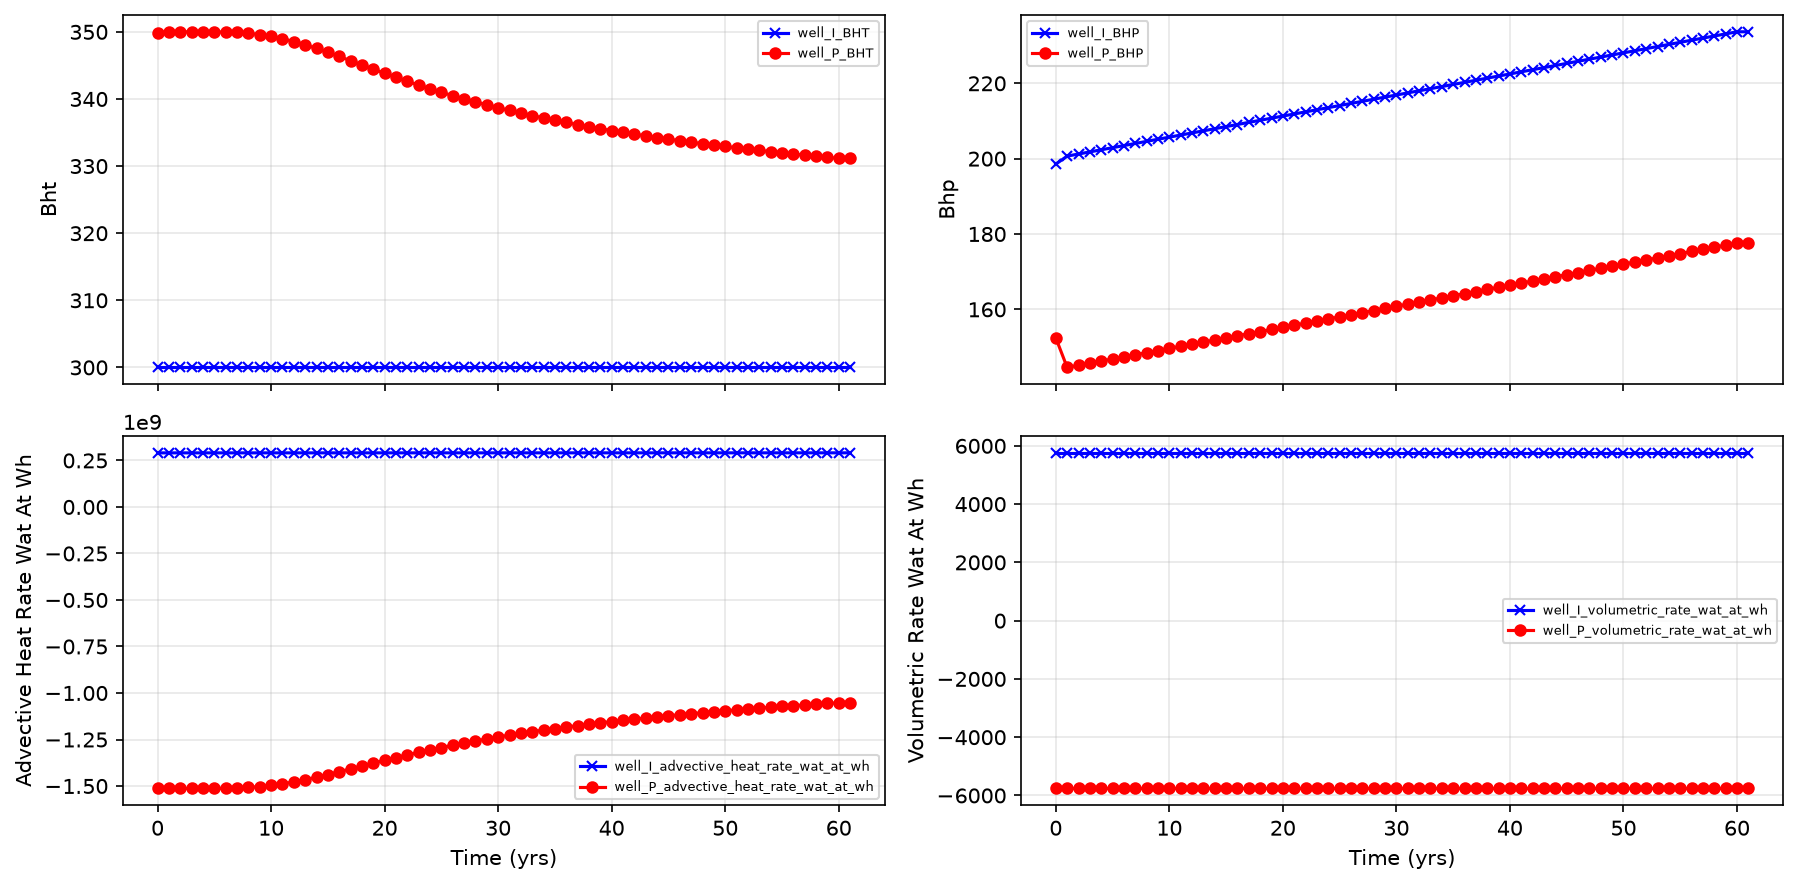

In [24]:
import matplotlib.pyplot as plt

# 1. Define the 2x2 plot layout
fig, ax = plt.subplots(2, 2, figsize=(12, 6), dpi=150, sharex=True)
ax_list = fig.axes

# 2. Define keywords matching your new column names
keywords = [
    'BHT',                          # Temperature (Injector & Producer)
    'BHP',                          # Bottom Hole Pressure
    'advective_heat_rate_wat_at_wh',# Heat rate / Energy at wellhead
    'volumetric_rate_wat_at_wh'     # Water rate at wellhead
]

# 3. Loop and plot for both wells using tdata
for i, key in enumerate(keywords):
    # Filter columns directly from tdata
    cols = tdata.filter(like=key).columns.tolist()
    
    if cols:
        tdata.plot(
            x='Time (yrs)',                # or 'Time (yrs)' depending on your tdata index/column
            y=cols,
            ax=ax_list[i],
            linestyle='-',
            style=['x', 'o'], 
            markersize=5,
            cmap='bwr'
        )
        ax_list[i].set_ylabel(key.replace('_', ' ').title())
        ax_list[i].legend(fontsize=6)
        ax_list[i].grid(alpha=0.3)

plt.tight_layout()
plt.show()

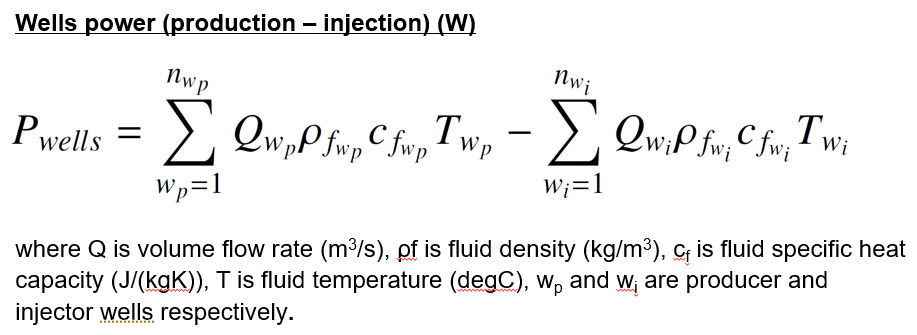

In [25]:
kJ_day_MW = 1/3.6e6/24
m3_day_m3_sec = 1 / (24 * 60 * 60)

# compute fluid properties for each well
tdata['well_PRD_rho'] = [PropsSI('D', 'P', P, 'T', T, 'IF97::Water') for P, T in zip(tdata['PRD : BHP (bar)']*0.1 * 1e6, tdata['PRD : temperature (K)'])]
tdata['well_PRD_cp']  = [PropsSI('C', 'P', P, 'T', T, 'IF97::Water') for P, T in zip(tdata['PRD : BHP (bar)']*0.1 * 1e6, tdata['PRD : temperature (K)'])]

tdata['well_INJ_rho'] = [PropsSI('D', 'P', P, 'T', T, 'IF97::Water') for P, T in zip(tdata['INJ : BHP (bar)']*0.1 * 1e6, tdata['INJ : temperature (K)'])]
tdata['well_INJ_cp']  = [PropsSI('C', 'P', P, 'T', T, 'IF97::Water') for P, T in zip(tdata['INJ : BHP (bar)']*0.1 * 1e6, tdata['INJ : temperature (K)'])]

# compute power for each well
tdata['well_PRD_power'] = 1e-6 * tdata['PRD : water rate (m3/day)']* m3_day_m3_sec * \
                             tdata['well_PRD_rho'] * tdata['well_PRD_cp'] * tdata['PRD : temperature (K)']

tdata['well_INJ_power'] = 1e-6 * tdata['INJ : water rate (m3/day)']* m3_day_m3_sec * \
                             tdata['well_INJ_rho'] * tdata['well_INJ_cp'] * tdata['INJ : temperature (K)']

# compute system power
tdata['system_power (MW)'] = abs(tdata['well_PRD_power']) - abs(tdata['well_INJ_power'])


# compute produced energy
tdata['Produced Energy (MWh)'] = tdata['system_power (MW)'] * tdata['Deltahours']

tdata.plot(x='Time (yrs)', y=['system_power (MW)'])

KeyError: 'PRD : BHP (bar)'

C:\Users\Acer\AppData\Local\Temp\ipykernel_5832\3027653615.py:19: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  tdata['well_PRD_rho'] = [PropsSI('D', 'P', P, 'T', T, 'IF97::Water') for P, T in zip(p_prd_pa, t_prd_k)]
C:\Users\Acer\AppData\Local\Temp\ipykernel_5832\3027653615.py:20: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  tdata['well_PRD_cp']  = [PropsSI('C', 'P', P, 'T', T, 'IF97::Water') for P, T in zip(p_prd_pa, t_prd_k)]
C:\Users\Acer\AppData\Local\Temp\ipykernel_5832\3027653615.py:22: PerformanceWarning: DataFrame is h

Time (yrs)
0 days                  NaN
365 days      106684.924553
730 days      106691.180741
1095 days     106697.666391
1460 days     106700.346873
1825 days     106686.318688
2190 days     106631.481300
2555 days     106502.649320
2920 days     106264.182829
3285 days     105885.858191
3650 days     105348.873133
4015 days     104648.425139
4380 days     103792.960241
4745 days     102801.178042
5110 days     101698.118808
5475 days     100511.380704
5840 days      99268.093684
6205 days      97992.870888
6570 days      96706.686471
6935 days      95426.488926
7300 days      94165.319680
7665 days      92932.727687
8030 days      91735.318349
8395 days      90577.325429
8760 days      89461.143620
9125 days      88387.786432
9490 days      87357.261749
9855 days      86368.868184
10220 days     85421.421988
10585 days     84513.426754
10950 days     83643.197872
11315 days     82808.952285
11680 days     82008.872192
12045 days     81241.149529
12410 days     80504.016441
12775 day

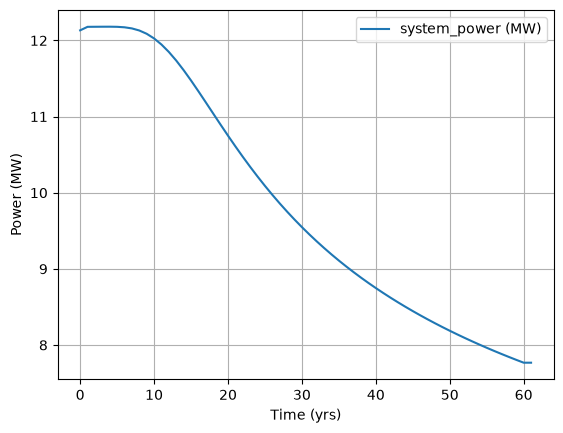

In [26]:
import sys

import numpy as np

# Unit conversion factors
kJ_day_MW = 1 / 3.6e6 / 24
m3_day_m3_sec = 1 / (24 * 60 * 60)

# Convert temperatures from Celsius to Kelvin if needed (assuming BHT is in °C)
# If your BHT is already in Kelvin, omit the + 273.15
t_inj_k = tdata['well_I_BHT'] 
t_prd_k = tdata['well_P_BHT'] 

# Pressure conversion: bar -> Pa (1 bar = 1e5 Pa)
p_inj_pa = tdata['well_I_BHP'] * 1e5
p_prd_pa = tdata['well_P_BHP'] * 1e5

# 1. Compute fluid properties for each well (I = Injector, P = Producer)
tdata['well_PRD_rho'] = [PropsSI('D', 'P', P, 'T', T, 'IF97::Water') for P, T in zip(p_prd_pa, t_prd_k)]
tdata['well_PRD_cp']  = [PropsSI('C', 'P', P, 'T', T, 'IF97::Water') for P, T in zip(p_prd_pa, t_prd_k)]

tdata['well_INJ_rho'] = [PropsSI('D', 'P', P, 'T', T, 'IF97::Water') for P, T in zip(p_inj_pa, t_inj_k)]
tdata['well_INJ_cp']  = [PropsSI('C', 'P', P, 'T', T, 'IF97::Water') for P, T in zip(p_inj_pa, t_inj_k)]

# 2. Compute thermal power for each well (using volumetric rate at wellhead)
# Note: 'well_P_volumetric_rate_wat_at_wh' is used as the updated equivalent for water rate
tdata['well_PRD_power'] = 1e-6 * tdata['well_P_volumetric_rate_wat_at_wh'] * m3_day_m3_sec * \
                             tdata['well_PRD_rho'] * tdata['well_PRD_cp'] * t_prd_k

tdata['well_INJ_power'] = 1e-6 * tdata['well_I_volumetric_rate_wat_at_wh'] * m3_day_m3_sec * \
                             tdata['well_INJ_rho'] * tdata['well_INJ_cp'] * t_inj_k

# 3. Compute net system thermal power (MW)
tdata['system_power (MW)'] = np.abs(tdata['well_PRD_power']) - np.abs(tdata['well_INJ_power'])

# 4. Compute cumulative produced energy (MWh)
tdata['Produced Energy (MWh)'] = tdata['system_power (MW)'] * tdata['Deltahours'] 

# 5. Plot net thermal power against time
tdata.plot(x='Time (yrs)', y=['system_power (MW)'], ylabel='Power (MW)', grid=True)

import pandas as pd
#pd.set_option('display.max_rows', None)  # Set threshold to maximum size to print all values
#print(tdata['system_power (MW)'][0:60])

import pandas as pd
pd.set_option('display.max_rows', None)  # Set threshold to maximum size to print all values
print(tdata['Produced Energy (MWh)'][0:60])

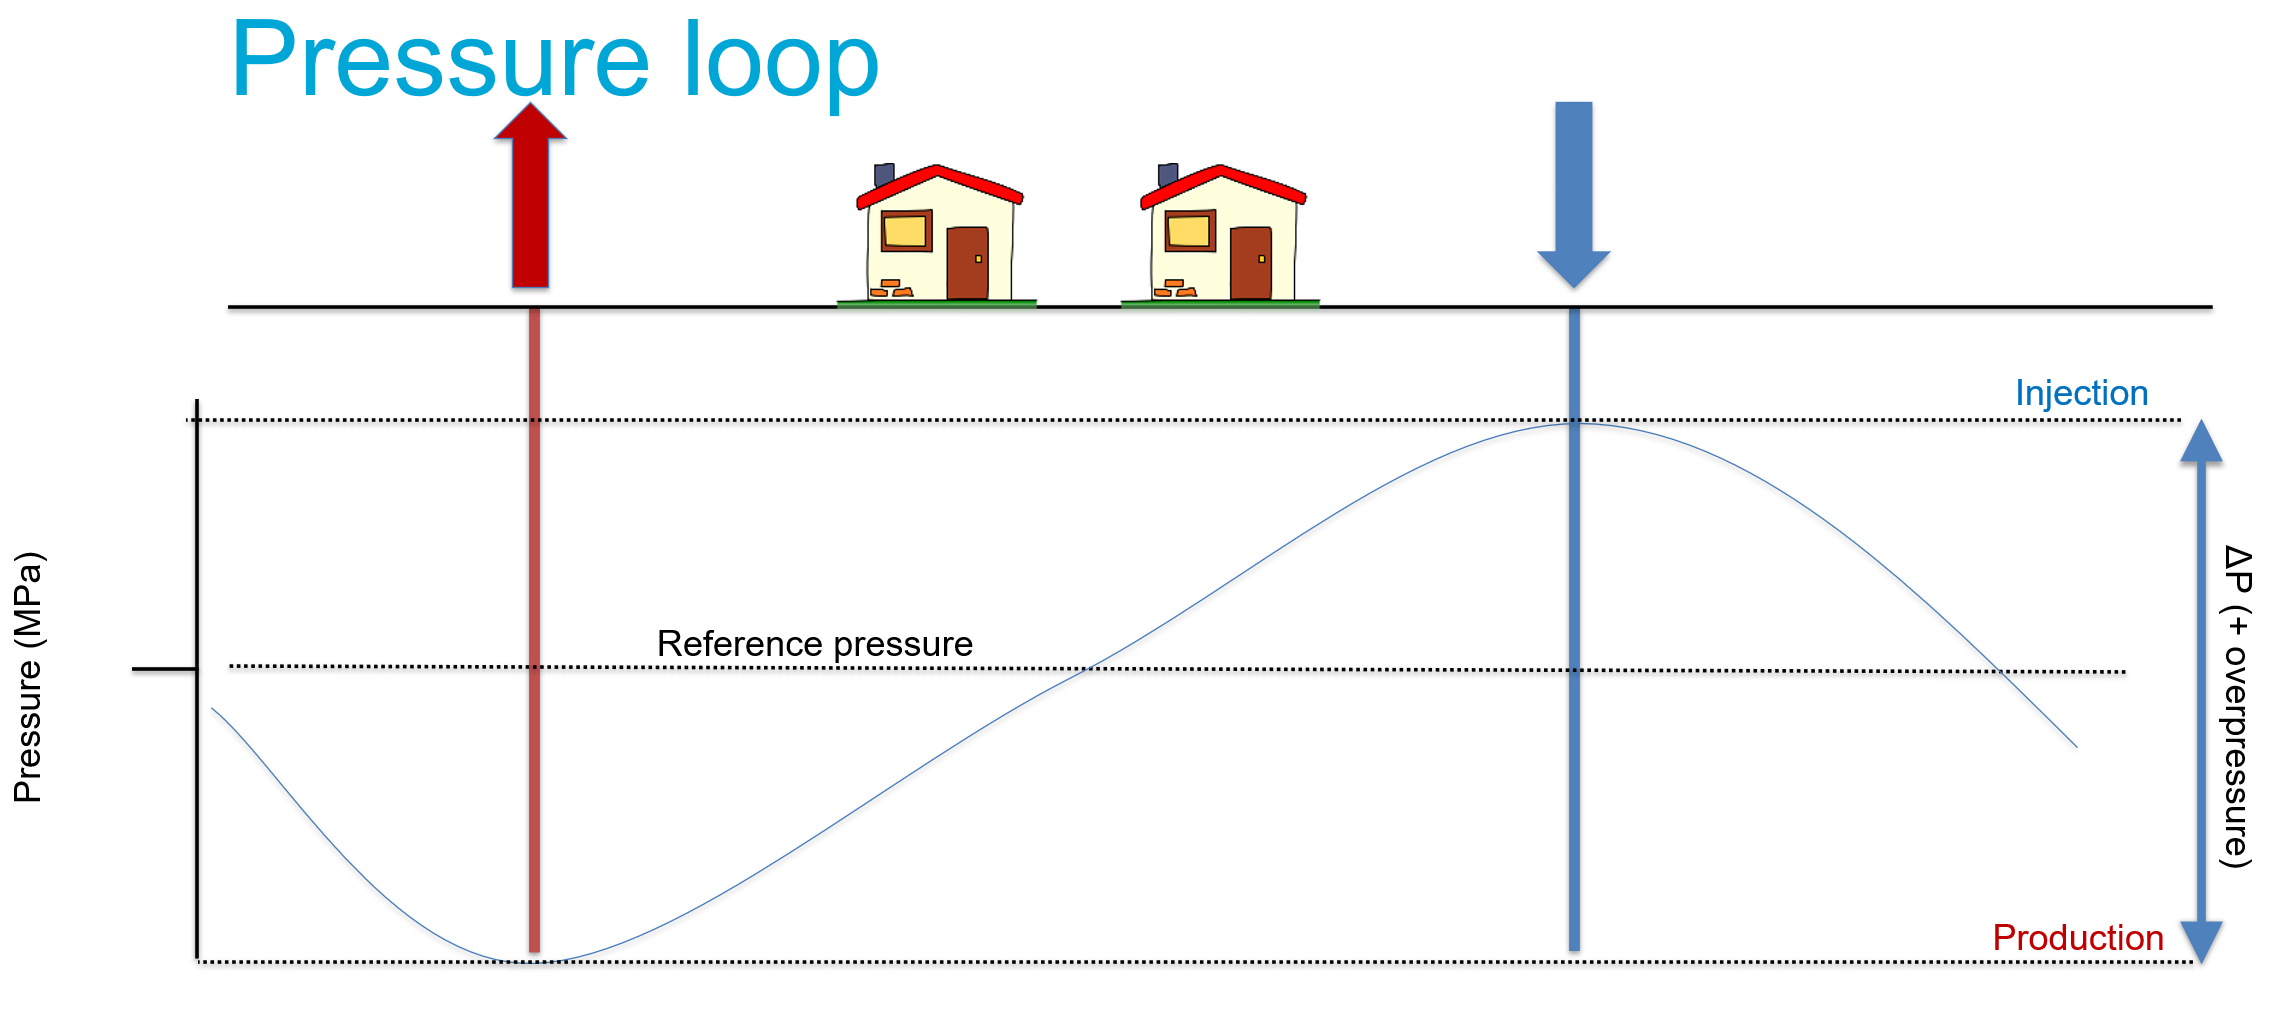

In [ ]:
# compute the pressure drop
tdata['Pump dp (MPa)'] = abs(tdata['well_P_BHP'] * 0.1) - abs(tdata['well_I_BHP']*0.1)

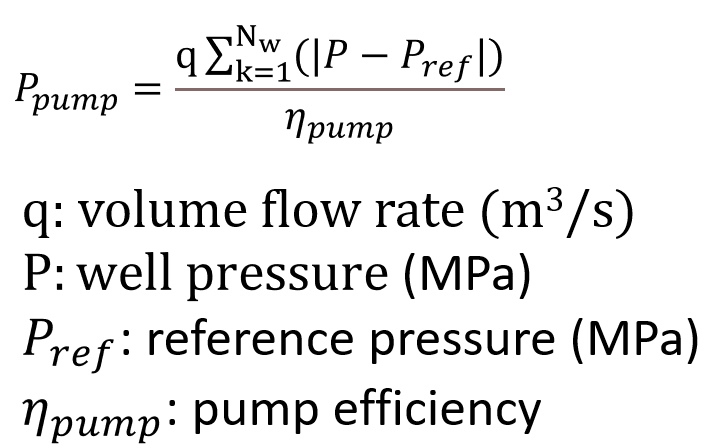

In [27]:
m3_day_m3_sec = 1 / (24 * 60 * 60)
pump_efficiency = 0.5

# compute the pumping power
tdata['Pump power (MW)'] = abs(tdata['Pump dp (MPa)']) * \
                             abs(tdata['well_I_volumetric_rate_wat_at_wh']) * m3_day_m3_sec / pump_efficiency

# compute the pumping costs
electricity_price = 120 # euro/MWh
tdata['OpEx_pump (\u20ac)'] = tdata['Pump power (MW)'] * tdata['Deltahours'] * electricity_price

KeyError: 'Pump dp (MPa)'

In [28]:
# assign the CapEx for drilling the wells
tdata['CapEx (\u20ac)'] = 0
tdata.loc[tdata.index == tdata.index[0], 'CapEx (\u20ac)'] = 2 * 1.5* 4113000

periodic_OpEx_rate = 0.03
# calculate variable OpEx costs
tdata['OpEx (\u20ac)'] = tdata['CapEx (\u20ac)'].cumsum() * periodic_OpEx_rate



C:\Users\Acer\AppData\Local\Temp\ipykernel_5832\495604892.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  tdata['CapEx (\u20ac)'] = 0
C:\Users\Acer\AppData\Local\Temp\ipykernel_5832\495604892.py:7: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  tdata['OpEx (\u20ac)'] = tdata['CapEx (\u20ac)'].cumsum() * periodic_OpEx_rate


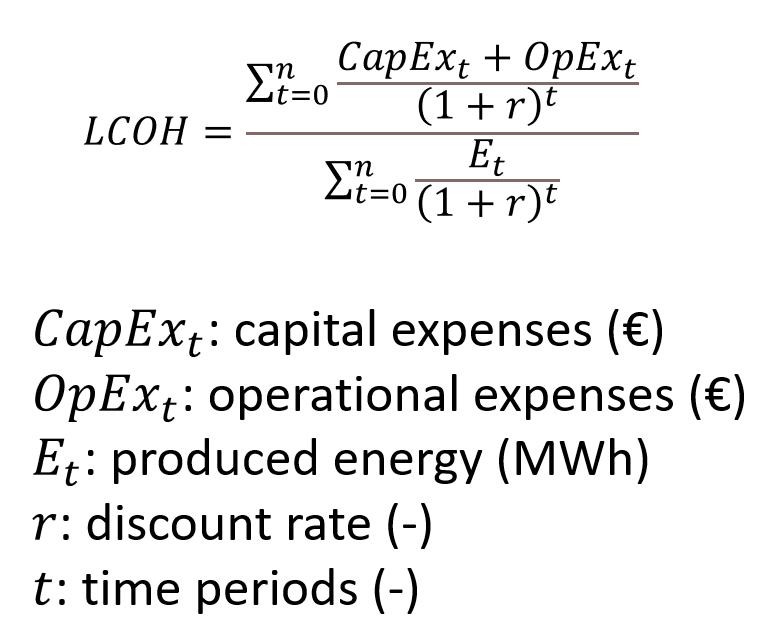

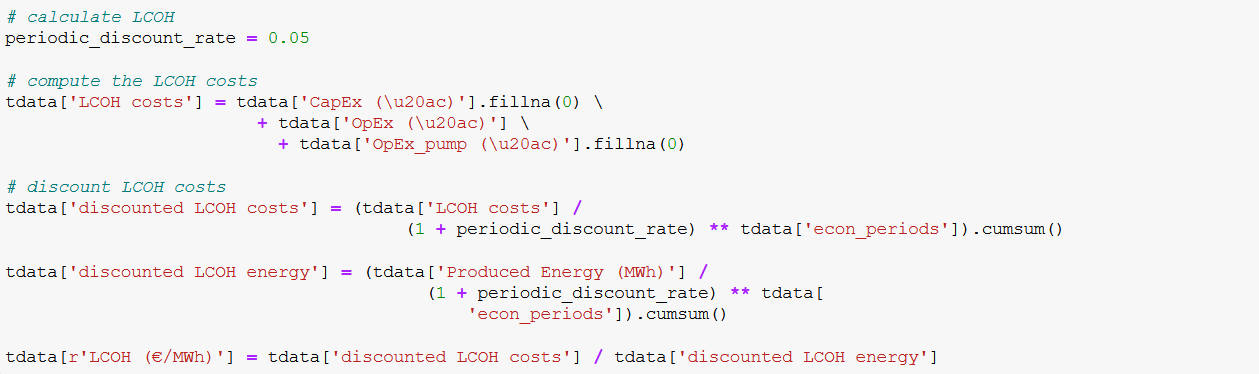

In [29]:
# calculate LCOH
periodic_discount_rate = 0.05

# compute the LCOH costs
tdata['LCOH costs'] = tdata['CapEx (\u20ac)'].fillna(0) \
                        + tdata['OpEx (\u20ac)'] \
                          + tdata['OpEx_pump (\u20ac)'].fillna(0)

# discount LCOH costs
tdata['discounted LCOH costs'] = (tdata['LCOH costs'] /
                                      (1 + periodic_discount_rate) ** tdata['econ_periods']).cumsum()

tdata['discounted LCOH energy'] = (tdata['Produced Energy (MWh)'] /
                                        (1 + periodic_discount_rate) ** tdata[
                                            'econ_periods']).cumsum()

tdata[r'LCOH (€/MWh)'] = tdata['discounted LCOH costs'] / tdata['discounted LCOH energy']



KeyError: 'OpEx_pump (€)'

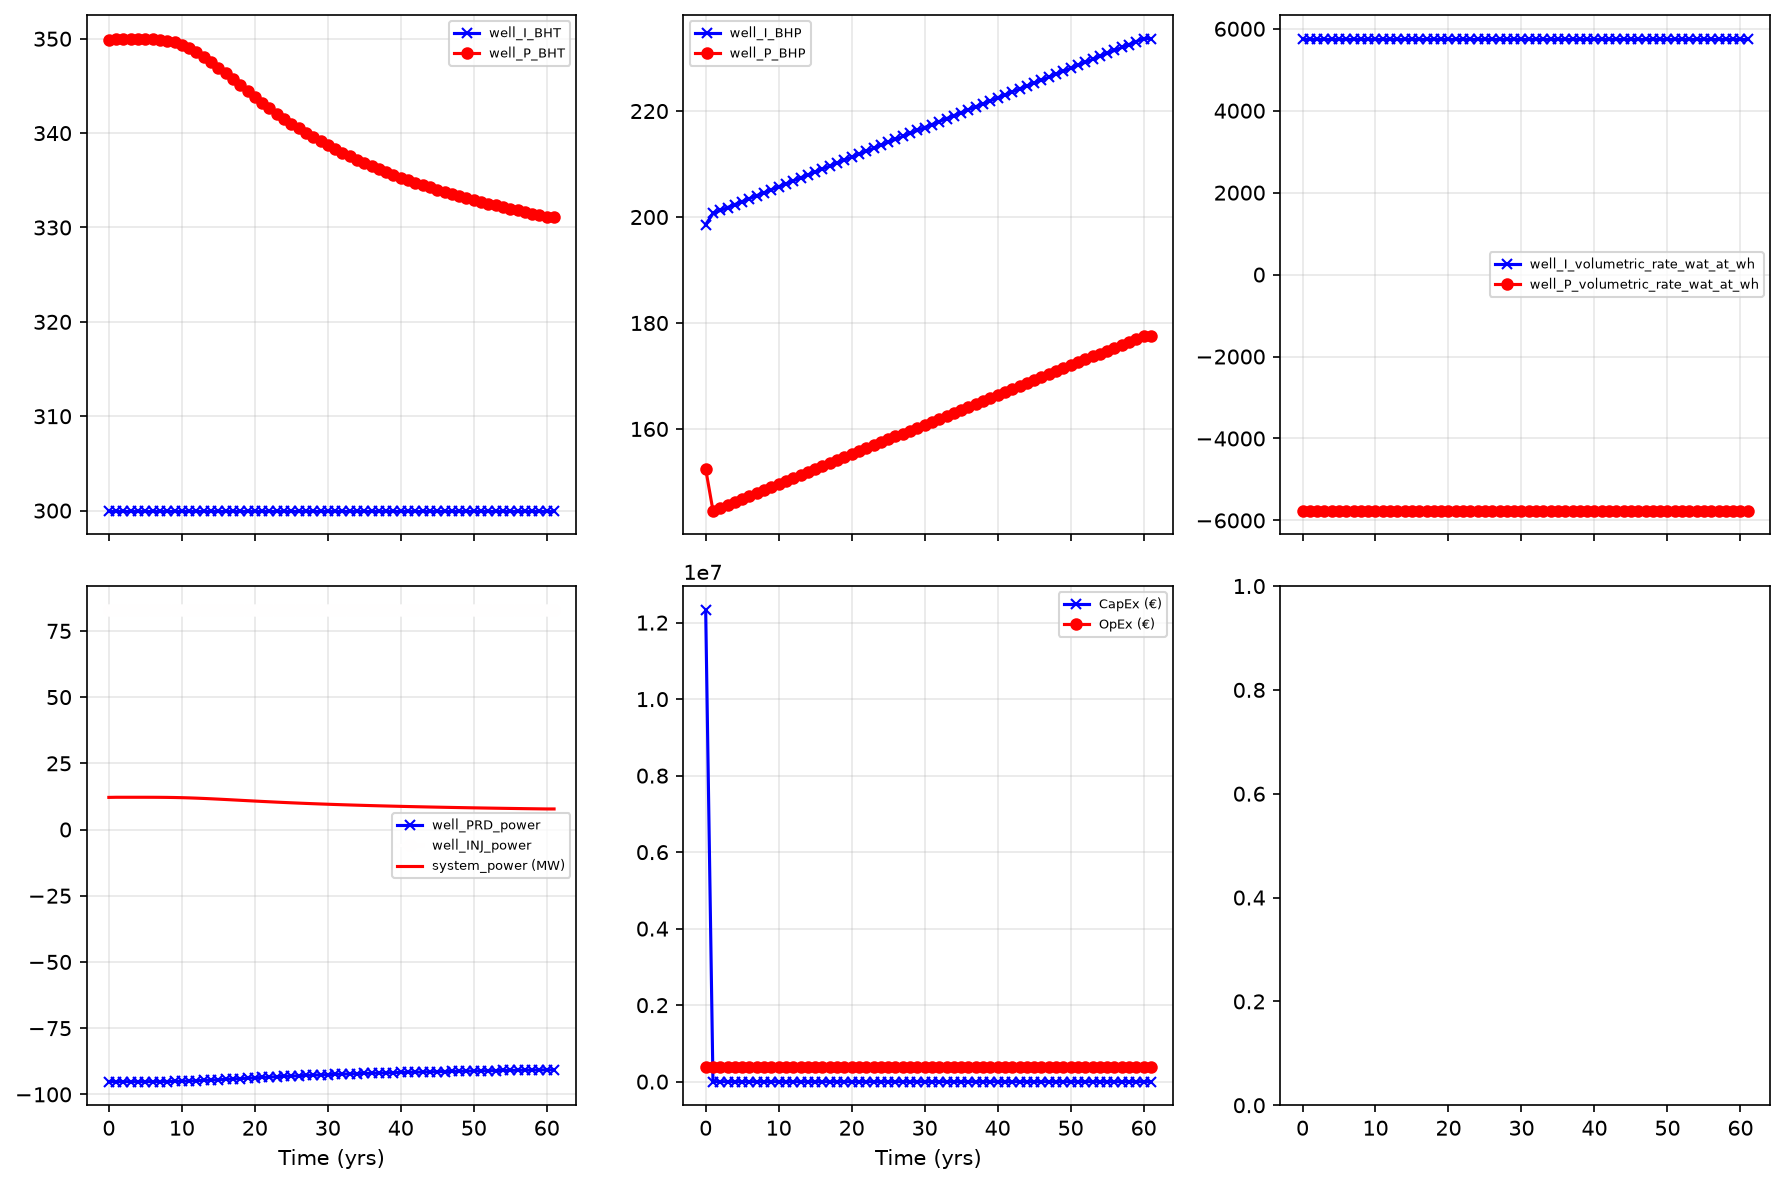

In [30]:
import matplotlib.pyplot as plt

# 1. Define a 2x3 subplot grid
fig, ax = plt.subplots(2, 3, figsize=(12, 8), dpi=150, sharex=True)
ax_list = fig.axes

# 2. Define keywords: updated first 3 to match new headers; kept power, Ex, and LCOH as-is
keywords = [
    'BHT',                           # Temperature (Injector & Producer)
    'BHP',                           # Bottom Hole Pressure
    'volumetric_rate_wat_at_wh',     # Water rate at wellhead
    'power',                         # Kept as-is
    'Ex',                            # Kept as-is
    'LCOH (€/MWh)'                   # Kept as-is
]

# 3. Plot each keyword
for i, key in enumerate(keywords):
    # Filter matching columns from tdata
    cols = tdata.filter(like=key).columns.tolist()
    
    if cols:
        tdata.plot(
            x='Time (yrs)',                # Updated to 'time' (use 'Time (yrs)' if preferred)
            y=cols,
            ax=ax_list[i],
            linestyle='-',
            style=['x', 'o'],
            markersize=5,
            cmap='bwr'
        )
        ax_list[i].legend(fontsize=6)
        ax_list[i].grid(alpha=0.3)
        
    # LCOH annotation handling
    if key == 'LCOH (€/MWh)' and 'LCOH (€/MWh)' in tdata.columns:
        ax_list[i].annotate(
            '%0.2f @ time: %.2f yrs' % (tdata[key].iloc[-1], tdata['Time (yrs)'].iloc[-1]),
            xy=(0.5, 0.5), va='center', ha='center',
            xycoords='axes fraction'
        )

plt.tight_layout()
plt.show()

C:\Users\Acer\AppData\Local\Temp\ipykernel_5832\3049573177.py:46: UserWarning: Tight layout not applied. tight_layout cannot make Axes height small enough to accommodate all Axes decorations.
  plt.tight_layout()


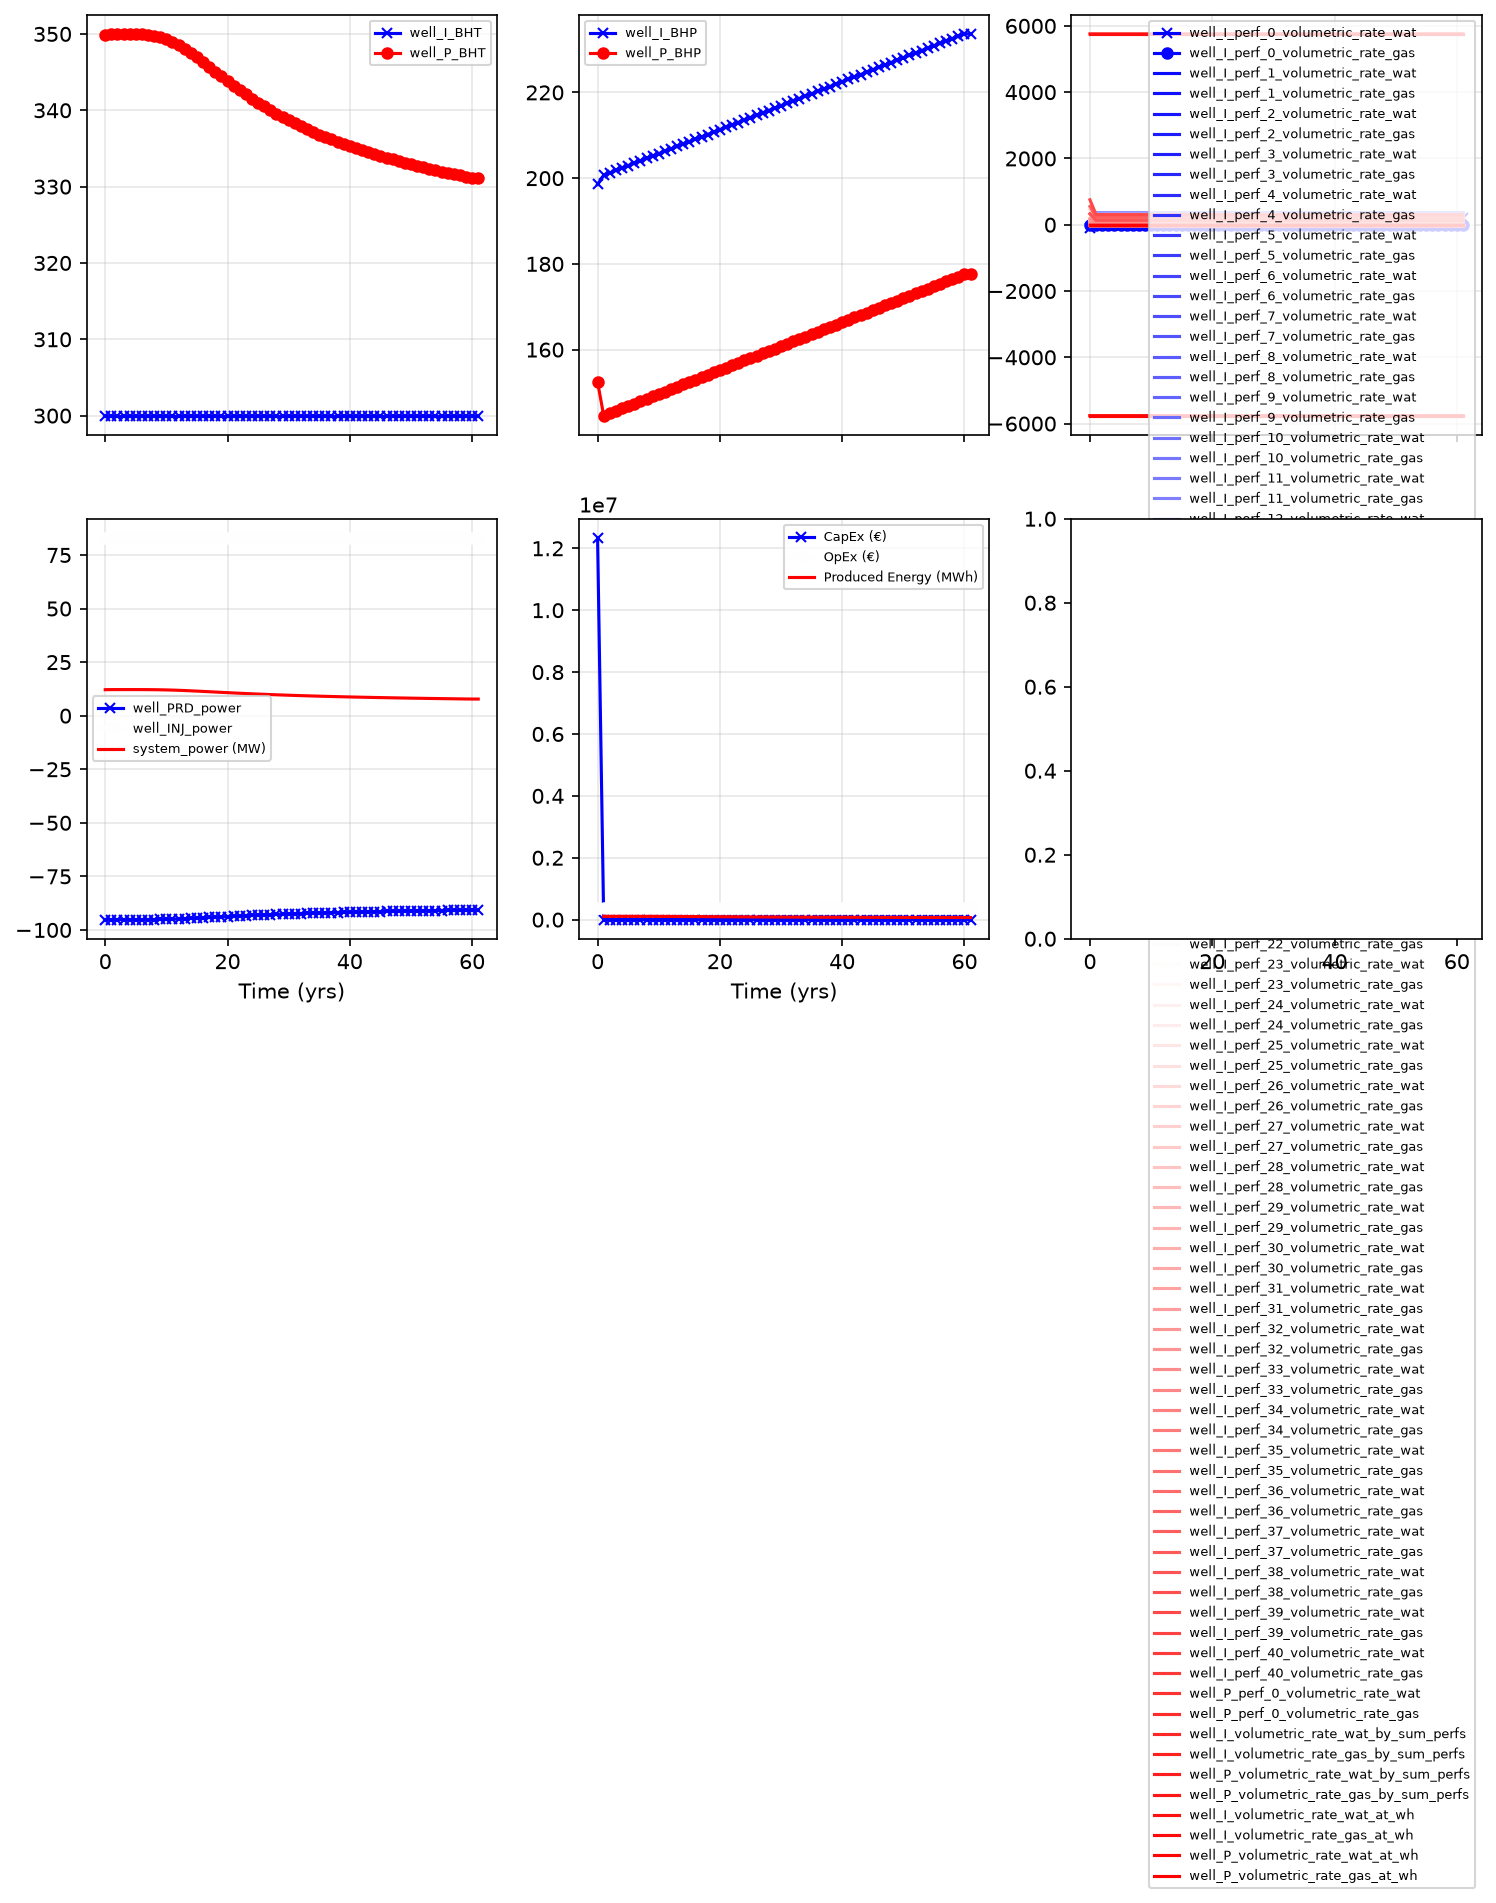

In [32]:
# final overview plot using only columns that actually exist
fig, ax = plt.subplots(2, 3, figsize=(12, 8), dpi=150, sharex=True)
ax_list = fig.axes

keyword_map = {
    'temperature': ['BHT', 'temperature'],
    'BHP': ['BHP'],
    'water rate': ['volumetric_rate', 'water rate', 'water_rate'],
    'power': ['power', 'system_power'],
    'Ex': ['Ex', 'Produced Energy', 'OpEx', 'CapEx'],
    'LCOH (€/MWh)': ['LCOH', 'LCOH (€/MWh)']
}

for i, key in enumerate(['temperature', 'BHP', 'water rate', 'power', 'Ex', 'LCOH (€/MWh)']):
    cols = []
    for pattern in keyword_map.get(key, [key]):
        cols.extend(tdata.filter(like=pattern).columns.tolist())
    cols = list(dict.fromkeys(cols))  # remove duplicates while preserving order

    if not cols:
        continue

    tdata.plot(
        x='Time (yrs)',
        y=cols,
        ax=ax_list[i],
        linestyle='-',
        style=['x', 'o'],
        markersize=5,
        cmap='bwr'
    )
    ax_list[i].legend(fontsize=6)
    ax_list[i].grid(alpha=0.3)

    if key == 'LCOH (€/MWh)' and 'LCOH (€/MWh)' in tdata.columns:
        last_val = tdata['LCOH (€/MWh)'].dropna().iloc[-1]
        last_time = tdata['Time (yrs)'].dropna().iloc[-1]
        ax_list[i].annotate(
            f'{last_val:0.2f} @ time: {last_time:0.2f} yrs',
            xy=(0.5, 0.5),
            xycoords='axes fraction',
            va='center',
            ha='center'
        )

plt.tight_layout()
plt.show()

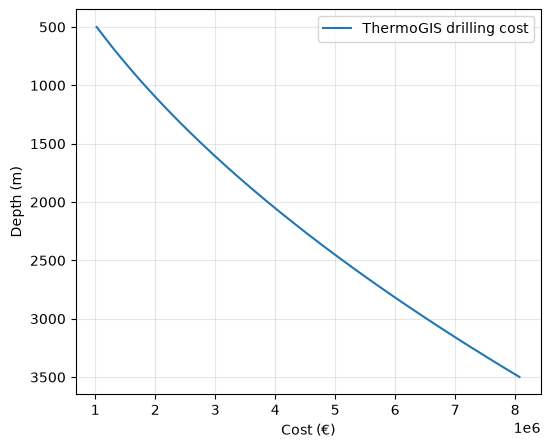

In [ ]:
def drillingcostnl(depth):
    """
    Calculate the cost of drilling as a function of depth
    Reference source:
        https://www.thermogis.nl/en/economic-model

    :param depth: float
        measured depth along hole in meters

    :return: float
        costs in euros
    """
    drilling_cost_nl = 375000 + 1150 * depth + 0.3 * depth ** 2
    return(drilling_cost_nl)

depth = np.arange(500, 3500, 1)
costs = drillingcostnl(depth)

fig, ax = plt.subplots(figsize=(6,5))
ax.plot(costs, depth, label='ThermoGIS drilling cost')
ax.set_xlabel('Cost (€)')
ax.set_ylabel('Depth (m)')
ax.grid(alpha=0.3)
ax.legend()
ax.invert_yaxis()

#### Importing the "new" DARTS output files, a working example ####

In [ ]:
tdata = pd.read_excel(flist[-1])

In [ ]:
tdata

,Unnamed: 0,time,well_PRD_BHP,well_PRD_BHT,well_INJ_BHP,well_INJ_BHT,well_PRD_perf_0_molar_rate_water,well_PRD_perf_0_molar_rate_steam,well_PRD_perf_1_molar_rate_water,well_PRD_perf_1_molar_rate_steam,...,well_INJ_perf_9_advective_heat_rate_water,well_INJ_perf_9_advective_heat_rate_steam,well_PRD_advective_heat_rate_water_by_sum_perfs,well_PRD_advective_heat_rate_steam_by_sum_perfs,well_INJ_advective_heat_rate_water_by_sum_perfs,well_INJ_advective_heat_rate_steam_by_sum_perfs,well_PRD_advective_heat_rate_water_at_wh,well_PRD_advective_heat_rate_steam_at_wh,well_INJ_advective_heat_rate_water_at_wh,well_INJ_advective_heat_rate_steam_at_wh
0,0,0.01,143.935571,355.404470,300.0,300.000115,-1125.629864,0,-1144.555928,0,...,2.666898e+07,0,-1.028711e+10,0,1.291238e+10,0,-9.413699e+09,0,1.350920e+10,0
1,1,0.03,135.641596,355.376507,300.0,300.000115,-1273.803883,0,-1285.813699,0,...,2.654857e+07,0,-1.027688e+10,0,1.192567e+10,0,-9.404206e+09,0,1.252225e+10,0
2,2,0.07,129.912396,355.358645,300.0,300.000115,-1355.981723,0,-1352.656691,0,...,2.632076e+07,0,-1.026974e+10,0,1.131608e+10,0,-9.397598e+09,0,1.191270e+10,0
3,3,0.15,125.480881,355.345887,300.0,300.000115,-1386.263736,0,-1356.479707,0,...,2.591484e+07,0,-1.026416e+10,0,1.089741e+10,0,-9.392423e+09,0,1.149411e+10,0
4,4,0.31,121.751312,355.339066,300.0,300.000115,-1365.716725,0,-1301.892534,0,...,2.525724e+07,0,-1.025933e+10,0,1.058894e+10,0,-9.387896e+09,0,1.118574e+10,0
5,5,0.63,118.685507,355.338103,300.0,300.000115,-1295.404130,0,-1204.850801,0,...,2.433559e+07,0,-1.025511e+10,0,1.037779e+10,0,-9.383961e+09,0,1.097477e+10,0
6,6,1.27,116.384746,355.348420,300.0,300.000115,-1191.965247,0,-1099.225199,0,...,2.325709e+07,0,-1.025146e+10,0,1.024733e+10,0,-9.380509e+09,0,1.084463e+10,0
7,7,2.55,114.848448,355.376955,300.0,300.000115,-1082.186215,0,-1016.284083,0,...,2.219509e+07,0,-1.024808e+10,0,1.015410e+10,0,-9.377233e+09,0,1.075198e+10,0
8,8,5.11,113.925997,355.431016,300.0,300.000115,-990.462345,0,-963.955280,0,...,2.127282e+07,0,-1.024446e+10,0,1.004119e+10,0,-9.373611e+09,0,1.064003e+10,0
9,9,10.23,113.385710,355.512922,300.0,300.000115,-933.585992,0,-936.609876,0,...,2.058156e+07,0,-1.024019e+10,0,9.842389e+09,0,-9.369250e+09,0,1.044260e+10,0


In [ ]:
tdata.columns.tolist()

['Unnamed: 0',
 'time',
 'well_PRD_BHP',
 'well_PRD_BHT',
 'well_INJ_BHP',
 'well_INJ_BHT',
 'well_PRD_perf_0_molar_rate_water',
 'well_PRD_perf_0_molar_rate_steam',
 'well_PRD_perf_1_molar_rate_water',
 'well_PRD_perf_1_molar_rate_steam',
 'well_PRD_perf_2_molar_rate_water',
 'well_PRD_perf_2_molar_rate_steam',
 'well_PRD_perf_3_molar_rate_water',
 'well_PRD_perf_3_molar_rate_steam',
 'well_PRD_perf_4_molar_rate_water',
 'well_PRD_perf_4_molar_rate_steam',
 'well_PRD_perf_5_molar_rate_water',
 'well_PRD_perf_5_molar_rate_steam',
 'well_PRD_perf_6_molar_rate_water',
 'well_PRD_perf_6_molar_rate_steam',
 'well_PRD_perf_7_molar_rate_water',
 'well_PRD_perf_7_molar_rate_steam',
 'well_PRD_perf_8_molar_rate_water',
 'well_PRD_perf_8_molar_rate_steam',
 'well_PRD_perf_9_molar_rate_water',
 'well_PRD_perf_9_molar_rate_steam',
 'well_INJ_perf_0_molar_rate_water',
 'well_INJ_perf_0_molar_rate_steam',
 'well_INJ_perf_1_molar_rate_water',
 'well_INJ_perf_1_molar_rate_steam',
 'well_INJ_perf_2_mo

In [ ]:
# list the collumn names that should be removed
perf_gridcells = tdata.filter(like='perf').columns.tolist()
molar_gridcells = tdata.filter(like='molar').columns.tolist()

# remove collumns from data
tdata.drop(columns=perf_gridcells + molar_gridcells, inplace=True)

tdata.columns.tolist()

['Unnamed: 0',
 'time',
 'well_PRD_BHP',
 'well_PRD_BHT',
 'well_INJ_BHP',
 'well_INJ_BHT',
 'well_PRD_mass_rate_water_at_wh',
 'well_PRD_mass_rate_steam_at_wh',
 'well_INJ_mass_rate_water_at_wh',
 'well_INJ_mass_rate_steam_at_wh',
 'well_PRD_volumetric_rate_water_at_wh',
 'well_PRD_volumetric_rate_steam_at_wh',
 'well_INJ_volumetric_rate_water_at_wh',
 'well_INJ_volumetric_rate_steam_at_wh',
 'well_PRD_advective_heat_rate_water_at_wh',
 'well_PRD_advective_heat_rate_steam_at_wh',
 'well_INJ_advective_heat_rate_water_at_wh',
 'well_INJ_advective_heat_rate_steam_at_wh']

<Axes: xlabel='time'>

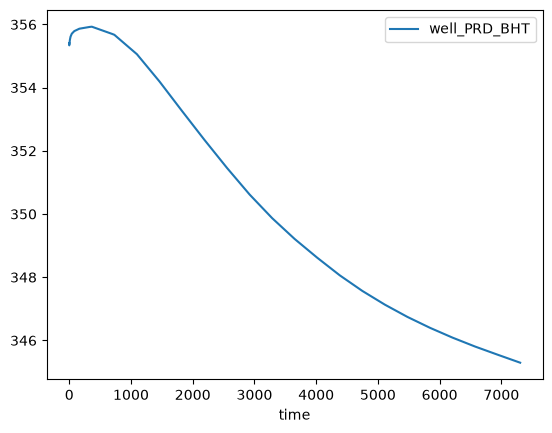

In [ ]:
tdata.plot(x='time', y=['well_PRD_BHT'])

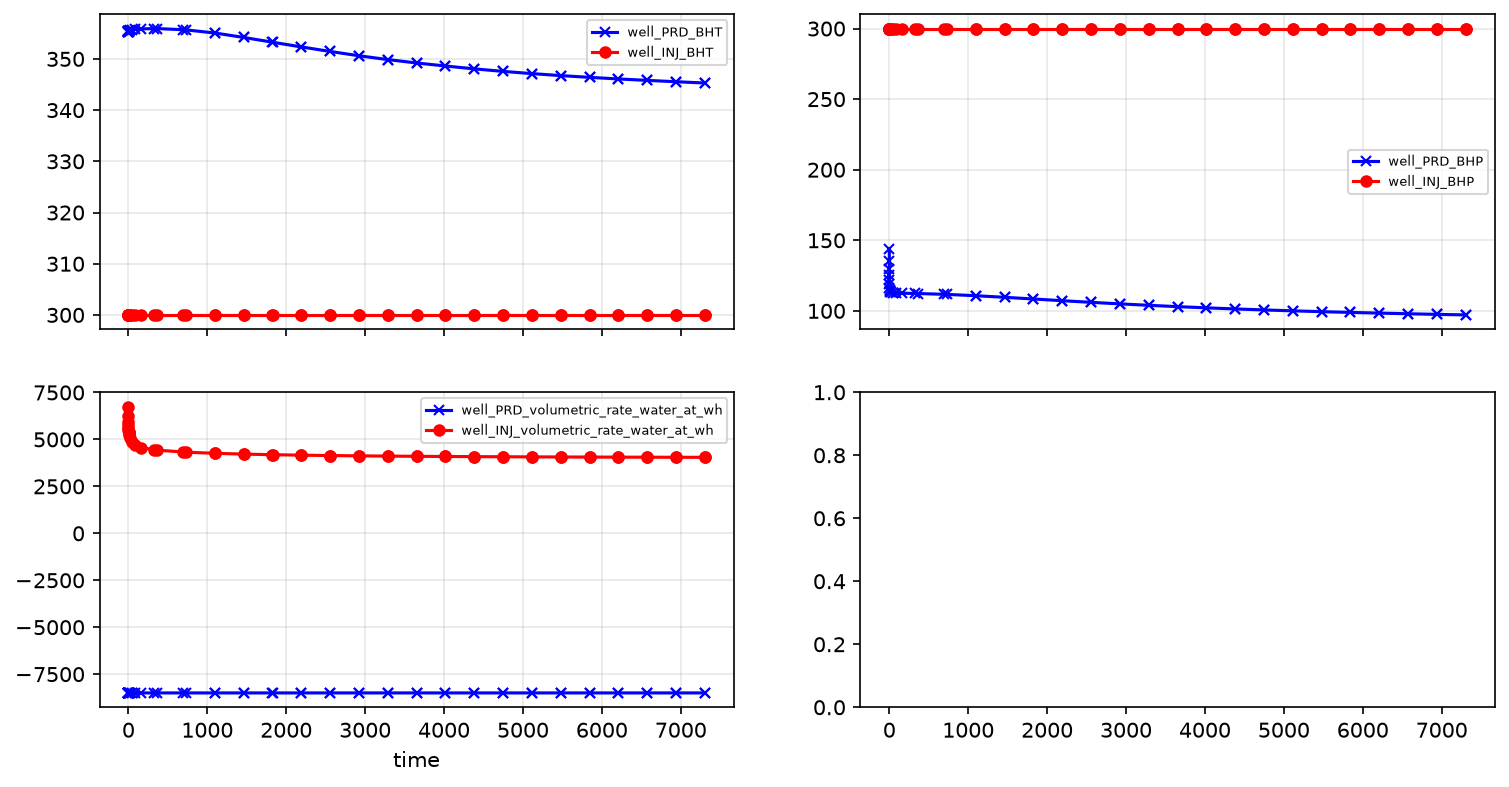

In [ ]:

# do a quick plot to get an overview of our treated data
# define a plot
fig, ax = plt.subplots(2,2, figsize=(12,6), dpi=150, sharex=True)
# get plot axes
ax_list = fig.axes

# plot a few keywords in pairs for both wells
for i, key in enumerate(['BHT', 'BHP','volumetric_rate_water']):
    tdata.plot(x='time',
              y=tdata.filter(like=key).columns.tolist(),
              ax=ax_list[i],
              linestyle='-',
              style=['x', 'o'], 
              markersize=5,
              cmap='bwr')
    ax_list[i].legend(fontsize=6)
    ax_list[i].grid(alpha=0.3)

In [ ]:

tdata['well_PRD_rho'] = [PropsSI('D', 'P', P, 'T', T, 'Water') for P, T in zip(tdata['well_PRD_BHP']*0.1 * 1e6, tdata['well_PRD_BHT'])]
tdata['well_PRD_cp']  = [PropsSI('C', 'P', P, 'T', T, 'Water') for P, T in zip(tdata['well_PRD_BHP']*0.1 * 1e6, tdata['well_PRD_BHT'])]

tdata['well_INJ_rho'] = [PropsSI('D', 'P', P, 'T', T, 'Water') for P, T in zip(tdata['well_INJ_BHP']*0.1 * 1e6, tdata['well_INJ_BHT'])]
tdata['well_INJ_cp']  = [PropsSI('C', 'P', P, 'T', T, 'Water') for P, T in zip(tdata['well_INJ_BHP']*0.1 * 1e6, tdata['well_INJ_BHT'])]

tdata['well_PRD_power'] = 1e-6 * tdata['well_PRD_volumetric_rate_water_at_wh']* m3_day_m3_sec * \
                             tdata['well_PRD_rho'] * tdata['well_PRD_cp'] * tdata['well_PRD_BHT']

tdata['well_INJ_power'] = 1e-6 * tdata['well_INJ_volumetric_rate_water_at_wh']* m3_day_m3_sec * \
                             tdata['well_INJ_rho'] * tdata['well_INJ_cp'] * tdata['well_INJ_BHT']

tdata['system_power_MW'] = abs(tdata['well_PRD_power']) - abs(tdata['well_INJ_power'])

In [ ]:
tdata.head()

,Unnamed: 0,time,well_PRD_BHP,well_PRD_BHT,well_INJ_BHP,well_INJ_BHT,well_PRD_mass_rate_water_at_wh,well_PRD_mass_rate_steam_at_wh,well_INJ_mass_rate_water_at_wh,well_INJ_mass_rate_steam_at_wh,...,well_PRD_advective_heat_rate_steam_at_wh,well_INJ_advective_heat_rate_water_at_wh,well_INJ_advective_heat_rate_steam_at_wh,well_PRD_rho,well_PRD_cp,well_INJ_rho,well_INJ_cp,well_PRD_power,well_INJ_power,system_power_MW
0,0,0.01,143.935571,355.404470,300.0,300.000115,-8.301718e+06,0,6.814009e+06,0,...,0,1.350920e+10,0,976.692251,4168.335797,1009.5708,4104.592415,-142.347322,97.116568,45.230754
1,1,0.03,135.641596,355.376507,300.0,300.000115,-8.298805e+06,0,6.316196e+06,0,...,0,1.252225e+10,0,976.349160,4169.999869,1009.5708,4104.592415,-142.342573,90.021494,52.321079
2,2,0.07,129.912396,355.358645,300.0,300.000115,-8.296808e+06,0,6.008741e+06,0,...,0,1.191270e+10,0,976.110840,4171.154907,1009.5708,4104.592415,-142.340222,85.639504,56.700719
3,3,0.15,125.480881,355.345887,300.0,300.000115,-8.295246e+06,0,5.797602e+06,0,...,0,1.149411e+10,0,975.925606,4172.051636,1009.5708,4104.592415,-142.338621,82.630248,59.708373
4,4,0.31,121.751312,355.339066,300.0,300.000115,-8.293917e+06,0,5.642064e+06,0,...,0,1.118574e+10,0,975.767108,4172.810992,1009.5708,4104.592415,-142.338721,80.413441,61.925280


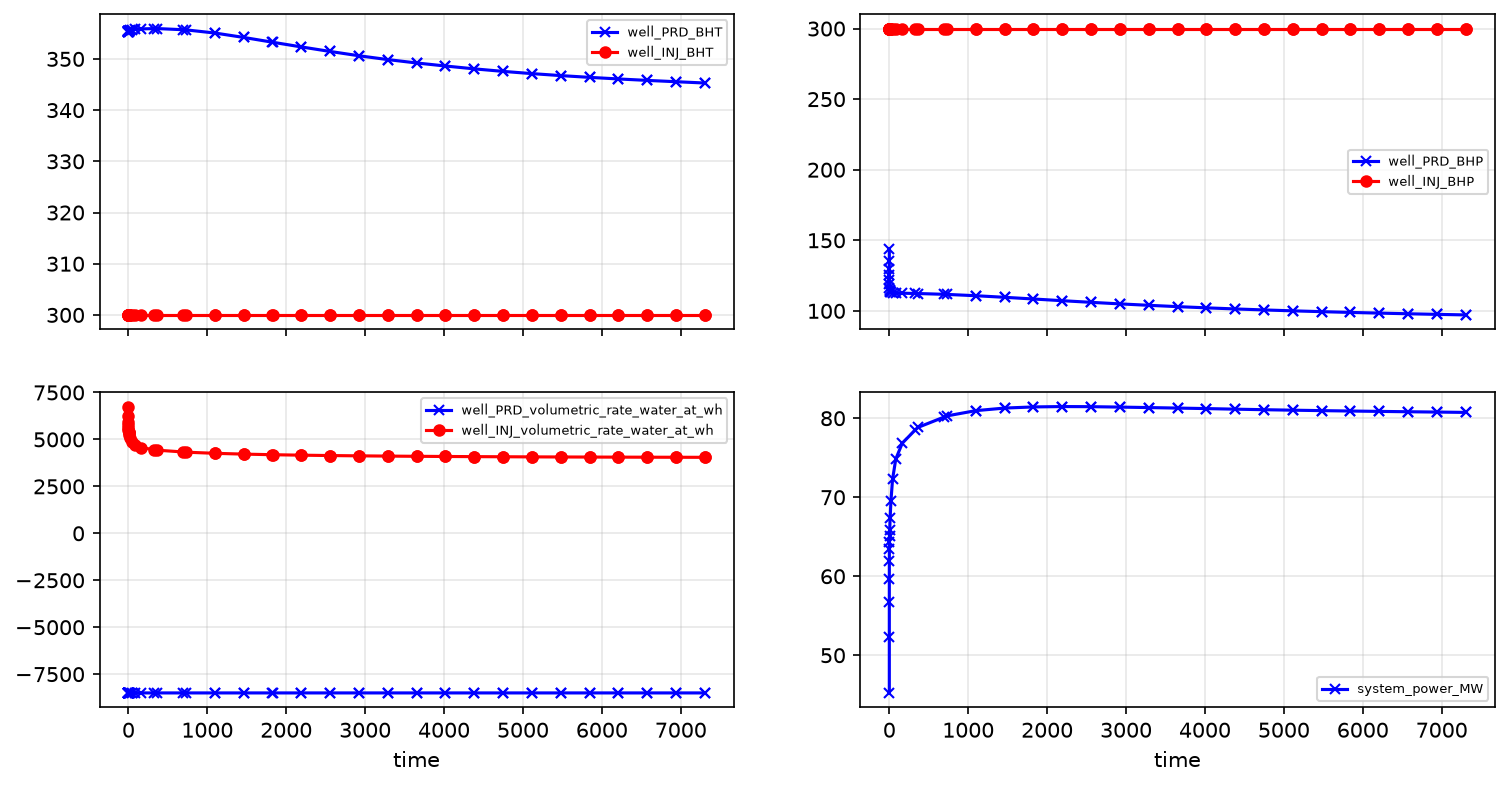

In [ ]:
fig, ax = plt.subplots(2,2, figsize=(12,6), dpi=150, sharex=True)
# get plot axes
ax_list = fig.axes

# plot a few keywords in pairs for both wells
for i, key in enumerate(['BHT', 'BHP','volumetric_rate_water', 'system_power_MW']):
    tdata.plot(x='time',
              y=tdata.filter(like=key).columns.tolist(),
              ax=ax_list[i],
              linestyle='-',
              style=['x', 'o'], 
              markersize=5,
              cmap='bwr')
    ax_list[i].legend(fontsize=6)
    ax_list[i].grid(alpha=0.3)

In [33]:
import numpy as np
import pandas as pd
import seaborn as sns
import os
import matplotlib.pyplot as plt

data = pd.read_excel('well_time_data.xlsx')

In [34]:
data

,time,well_I_BHP,well_I_BHT,well_P_BHP,well_P_BHT,well_I_perf_0_molar_rate_wat,well_I_perf_0_molar_rate_gas,well_I_perf_1_molar_rate_wat,well_I_perf_1_molar_rate_gas,well_I_perf_2_molar_rate_wat,...,well_P_perf_0_advective_heat_rate_wat,well_P_perf_0_advective_heat_rate_gas,well_I_advective_heat_rate_wat_by_sum_perfs,well_I_advective_heat_rate_gas_by_sum_perfs,well_P_advective_heat_rate_wat_by_sum_perfs,well_P_advective_heat_rate_gas_by_sum_perfs,well_I_advective_heat_rate_wat_at_wh,well_I_advective_heat_rate_gas_at_wh,well_P_advective_heat_rate_wat_at_wh,well_P_advective_heat_rate_gas_at_wh
0,0.000100,198.545650,300,152.429532,349.842250,-94967.280216,0,-0.001061,0,-76782.034077,...,-1.510732e+09,0,2.874551e+08,0,-1.510732e+09,0,2.905993e+08,0,-1.508982e+09,0
1,0.000220,198.883364,300,147.856051,349.866548,-56555.303868,0,-0.000693,0,-29541.698395,...,-1.509820e+09,0,2.921084e+08,0,-1.509820e+09,0,2.906015e+08,0,-1.509491e+09,0
2,0.000364,199.086818,300,145.586164,349.854881,-35314.440664,0,-0.000447,0,-4239.503053,...,-1.509346e+09,0,2.914437e+08,0,-1.509346e+09,0,2.906029e+08,0,-1.509163e+09,0
3,0.000537,199.229250,300,144.268396,349.845821,-20646.396809,0,-0.000259,0,12829.678054,...,-1.509071e+09,0,2.867252e+08,0,-1.509071e+09,0,2.906038e+08,0,-1.508917e+09,0
4,0.000744,199.339701,300,143.457974,349.839987,-9044.357237,0,-0.000105,0,26249.246757,...,-1.508902e+09,0,2.905534e+08,0,-1.508902e+09,0,2.906045e+08,0,-1.508759e+09,0
5,0.000993,199.430691,300,142.969222,349.836439,945.260733,0,0.000026,0,37965.349736,...,-1.508801e+09,0,2.904716e+08,0,-1.508801e+09,0,2.906051e+08,0,-1.508663e+09,0
6,0.001292,199.508326,300,142.697775,349.834488,10094.722957,0,0.000139,0,48985.362681,...,-1.508745e+09,0,2.906034e+08,0,-1.508745e+09,0,2.906056e+08,0,-1.508610e+09,0
7,0.001650,199.575923,300,142.571990,349.833623,18869.725130,0,0.000241,0,59854.969977,...,-1.508720e+09,0,2.906067e+08,0,-1.508720e+09,0,2.906061e+08,0,-1.508587e+09,0
8,0.002080,199.635386,300,142.539864,349.833467,27549.518910,0,0.000335,0,70844.575012,...,-1.508715e+09,0,2.906070e+08,0,-1.508715e+09,0,2.906065e+08,0,-1.508583e+09,0
9,0.002596,199.687834,300,142.564848,349.833752,36284.426298,0,0.000425,0,82061.292175,...,-1.508722e+09,0,2.906072e+08,0,-1.508722e+09,0,2.906068e+08,0,-1.508590e+09,0


In [35]:
Measured_depth = 2500 #meters

#CAPEX
Drilling_costs = 375000 +1150*Measured_depth +0.3*(Measured_depth)**2

Construction_costs = 0.5*Drilling_costs
Site_preparation_costs = 0.1*Drilling_costs
Equipment_costs = 0.2*Drilling_costs 

Capex = Drilling_costs + Construction_costs + Site_preparation_costs + Equipment_costs


#OPEX is 10% of CAPEX per year
Opex = 0.1 * Capex

#ABEX 
Abex = 0.05 * Capex

#CASHFLOW


revenue = 0
expenses =0
unit_price =0.1 #EUR/kWh
cum_production =0
operating_costs =0
capital_costs =0
royalty_rate =0
tax_rate =0.25
income_before_tax =0

cash_flow_in_year_k = revenue - expenses 
cash_flow_in_year_k = (unit_price * cum_production ) - (operating_costs + capital_costs) - (royalty_rate * unit_price *  cum_production) - (income_before_tax * tax_rate )

print("CAPEX: ", Capex /1e6, "million EUR")


CAPEX:  9.225 million EUR


In [37]:
# Array of annual system Power in MW from Year 1 to Year 60
data_60_years = tdata['system_power (MW)'].values[:60]
data_60_years

array([12.13276957, 12.17864436, 12.17935853, 12.1800989 , 12.18040489,
       12.1788035 , 12.17254353, 12.15783668, 12.13061448, 12.08742673,
       12.02612707, 11.94616725, 11.84851144, 11.7352943 , 11.60937429,
       11.47390191, 11.33197416, 11.18640079, 11.03957608, 10.89343481,
       10.74946572, 10.60875887, 10.4720683 , 10.33987733, 10.21245932,
       10.08992996,  9.97229015,  9.85945984,  9.75130388,  9.64765146,
        9.54831026,  9.45307674,  9.3617434 ,  9.27410383,  9.18995621,
        9.10910566,  9.03136567,  8.95655901,  8.88451819,  8.8150856 ,
        8.74811342,  8.68346343,  8.62100662,  8.56062285,  8.50220021,
        8.44563481,  8.39083011,  8.33769644,  8.28615054,  8.23611508,
        8.18751819,  8.14029304,  8.09437741,  8.04971335,  8.00624676,
        7.96392708,  7.92270701,  7.88254217,  7.8433909 ,  7.80521397])

In [39]:
#Array of MWh of energy per year from Year 1 to Year 60


MWh = tdata['Produced Energy (MWh)'][0:60]
MWh_array = np.array(MWh)

# Calculate revenue for all years
Revenue = MWh_array * unit_price * 1000 

# Print only Year 1 (index 0)
print( Revenue, "EUR")

[              nan 10668492.45526789 10669118.07412432 10669766.63905691
 10670034.68729498 10668631.86878766 10663148.12999254 10650264.93198242
 10626418.28286023 10588585.81909771 10534887.31329549 10464842.51385173
 10379296.02414805 10280117.80417944 10169811.88083099 10051138.07037836
  9926809.36841793  9799287.08875792  9670668.64705713  9542648.89258128
  9416531.96804229  9293272.76870437  9173531.83494735  9057732.54294006
  8946114.36195692  8838778.64315325  8735726.17489011  8636886.81841095
  8542142.19883553  8451342.67541435  8364319.78720015  8280895.22846075
  8200887.21918629  8124114.95292004  8050401.64411709  7979576.56091395
  7911476.32582736  7845945.69037706  7782837.93231846  7722014.98240474
  7663347.35926038  7606713.96723401  7552001.798709    7499105.61804334
  7447927.38239734  7398376.09272025  7350367.17224951  7303822.07724135
  7258667.87131627  7214836.80795512  7172265.93249314  7130896.69973102
  7090674.61474048  7051548.89561839  7013472.15795

Total CAPEX: 9.22 million EUR
Annual OPEX: 0.92 million EUR
Break-even occurs in Year: 7
Net Present Value (Undiscounted) at Year 60: 407.92 million EUR


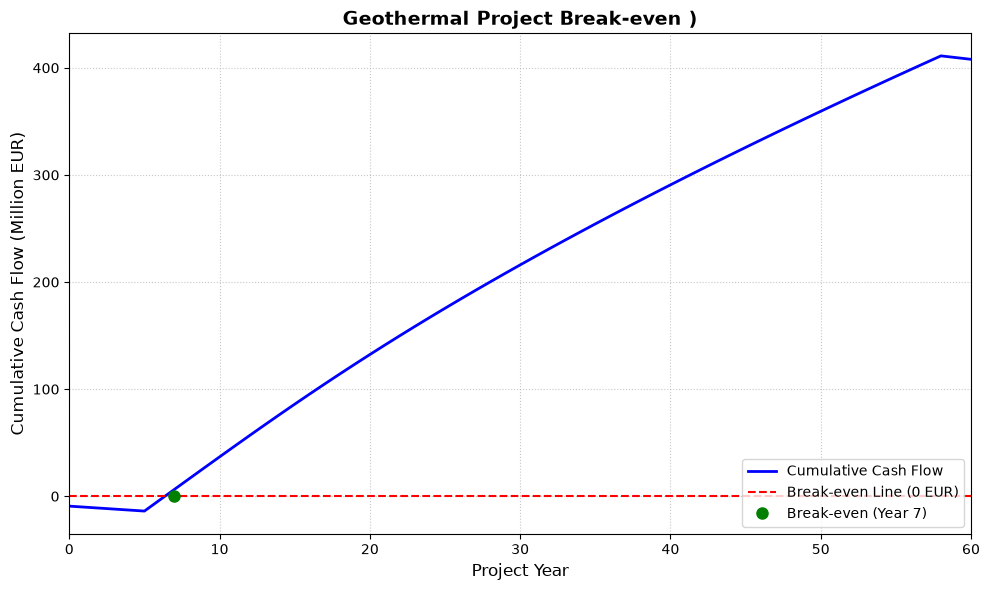

In [ ]:

Measured_depth = 2500 # meters
Drilling_costs = 375000 + 1150 * Measured_depth + 0.3 * (Measured_depth)**2
Construction_costs = 0.5 * Drilling_costs
Site_preparation_costs = 0.1 * Drilling_costs
Equipment_costs = 0.2 * Drilling_costs 

Capex = Drilling_costs + Construction_costs + Site_preparation_costs + Equipment_costs


Opex = 0.1 * Capex   # OPEX is 10% of CAPEX every year
Abex = 0.15 * Capex  # ABEX is 5% of CAPEX incurred at the end of life (Year 60)


unit_price = 0.15    # EUR/kWh
royalty_rate = 0.10  # 2% standard subsurface royalty estimate
tax_rate = 0.25     # 25.8% standard Dutch corporate tax rate

print(f"Total CAPEX: {Capex / 1e6:.2f} million EUR")
print(f"Annual OPEX: {Opex / 1e6:.2f} million EUR")

# --- 4. PRODUCTION ARRAY (Year 1 to 60) ---
MWh[:8] = [0] * 8
MWh[-2:] = [0] * 2
MWh_array = np.array(MWh)

# --- 5. CASH FLOW MODELING (Year 0 to 60) ---
years = np.arange(0, 61) # 61 elements (Year 0 through Year 60)
annual_cash_flows = np.zeros(61)

# Year 0: Investment occurs before production begins
annual_cash_flows[0] = -Capex

# Straight-line depreciation of CAPEX over 60 years
annual_depreciation = Capex / 60 

for i, prod_MWh in enumerate(MWh_array):
    year = i + 1
    
    # 1 MWh = 1000 kWh
    annual_revenue = prod_MWh * 1000 * unit_price
    
    # Deduct Royalties
    royalties = annual_revenue * royalty_rate
    
    # Earnings Before Interest, Taxes, Depreciation, and Amortization (EBITDA)
    ebitda = annual_revenue - Opex - royalties
    
    # Taxable Income = EBITDA minus Depreciation
    income_before_tax = ebitda - annual_depreciation
    
    # Calculate Corporate Tax (cannot be negative)
    tax = max(0, income_before_tax * tax_rate)
    
    # Net Operating Cash Flow
    net_cash_flow = ebitda - tax
    

        
 

    if year in [59, 60]:
        net_cash_flow -= (Abex / 2)
            
        # Add operating cash flow
    annual_cash_flows[year] += net_cash_flow

# Calculate cumulative cash flows for the break-even plot
cumulative_cash_flows = np.cumsum(annual_cash_flows)

# Determine Break-even Year (first year where cumulative cash flow turns positive)
break_even_year = np.argmax(cumulative_cash_flows > 0)
print(f"Break-even occurs in Year: {break_even_year}")
print(f"Net Present Value (Undiscounted) at Year 60: {cumulative_cash_flows[-1] / 1e6:.2f} million EUR")

# --- 6. BREAK-EVEN PLOT ---
plt.figure(figsize=(10, 6))

# Plot the cumulative cash flow line
plt.plot(years, cumulative_cash_flows / 1e6, color='b', linewidth=2, label='Cumulative Cash Flow')

# Plot the zero-line (break-even line)
plt.axhline(0, color='r', linestyle='--', label='Break-even Line (0 EUR)')

# Highlight the break-even point
plt.plot(break_even_year, 0, 'go', markersize=8, label=f'Break-even (Year {break_even_year})')

# Formatting
plt.title('Geothermal Project Break-even )', fontsize=14, fontweight='bold')
plt.xlabel('Project Year', fontsize=12)
plt.ylabel('Cumulative Cash Flow (Million EUR)', fontsize=12)
plt.xlim(0, 60)
plt.grid(True, linestyle=':', alpha=0.7)
plt.legend(loc='lower right')
plt.tight_layout()

# Show the plot
plt.show()

In [6]:
# Changed ABEX to 30% of CAPEX as requested
Abex = 0.30 * Capex

# ... (MWh array padding logic remains the same) ...

def calculate_cash_flow(unit_price, royalty_rate):
    annual_cash_flows = np.zeros(61)
    
    # Spread CAPEX evenly across the first 10 years (Years 0 to 9)
    for year in range(10):
        annual_cash_flows[year] -= Capex / 10
        
    annual_depreciation = Capex / 60 

    for i, prod_MWh in enumerate(MWh_array):
        year = i + 1
        annual_revenue = prod_MWh * 1000 * unit_price
        royalties = annual_revenue * royalty_rate
        ebitda = annual_revenue - Opex - royalties
        income_before_tax = ebitda - annual_depreciation
        tax = max(0, income_before_tax * 0.25)
        net_cash_flow = ebitda - tax
        
        # --- NEW ABEX LOGIC ---
        # Spread Abex over the last 2 years (Years 59 and 60)
        if year in [59, 60]:
            net_cash_flow -= (Abex / 2)
            
        # Add operating cash flow
        annual_cash_flows[year] += net_cash_flow
        
    return np.cumsum(annual_cash_flows)

59


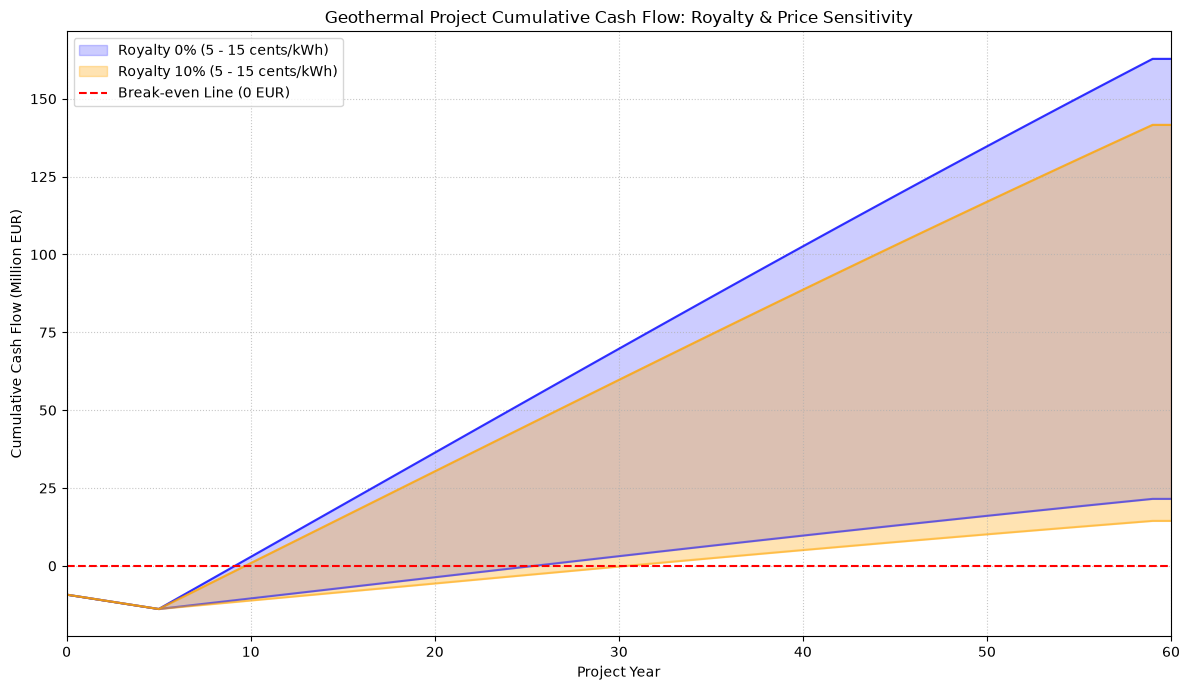

In [7]:
import numpy as np
import matplotlib.pyplot as plt

Measured_depth = 2500
Drilling_costs = 375000 + 1150 * Measured_depth + 0.3 * (Measured_depth)**2
Construction_costs = 0.5 * Drilling_costs
Site_preparation_costs = 0.1 * Drilling_costs
Equipment_costs = 0.2 * Drilling_costs 

Capex = Drilling_costs + Construction_costs + Site_preparation_costs + Equipment_costs
Opex = 0.1 * Capex
Abex =  0.05 * Capex

# Let's count MWh array length
MWh = [
    0,0,0,0,0,35557.544870, 35556.931177, 35556.443997, 35556.130896, 35555.936123,
    35555.830991, 35555.789027, 35555.774310, 35555.728290, 35555.555029,
    35555.107284, 35554.176844, 35552.491811, 35549.721719, 35545.489931,
    35539.391389, 35531.013049, 35519.954437, 35505.846130, 35488.364675,
    35467.243227, 35442.277763, 35413.329232, 35380.322282, 35343.241318,
    35302.124697, 35257.057755, 35208.165314, 35155.604127, 35099.555650,
    35040.219354, 34977.806782, 34912.536365, 34844.629052, 34774.304724,
    34701.779306, 34627.262549, 34550.956363, 34473.053625, 34393.737418,
    34313.180582, 34231.545525, 34148.984257, 34065.638571, 33981.640339,
    33897.111902, 33812.166493, 33726.908720, 33641.435032, 33555.834215,
    33470.187876, 33384.570899, 33299.051894, 33213.693638,
]
MWh_array = np.array(MWh)
print(len(MWh_array))

# Function to calculate cash flows
def calculate_cash_flow(unit_price, royalty_rate):
    annual_cash_flows = np.zeros(61)
    annual_cash_flows[0] = -Capex
    annual_depreciation = Capex / 60 

    for i, prod_MWh in enumerate(MWh_array):
        year = i + 1
        annual_revenue = prod_MWh * 1000 * unit_price
        royalties = annual_revenue * royalty_rate
        ebitda = annual_revenue - Opex - royalties
        income_before_tax = ebitda - annual_depreciation
        tax = max(0, income_before_tax * 0.25)
        net_cash_flow = ebitda - tax
        if year == 60:
            net_cash_flow -= Abex
        annual_cash_flows[year] = net_cash_flow
    return np.cumsum(annual_cash_flows)

prices = [0.05, 0.15]
cf_0_low = calculate_cash_flow(0.05, 0.0)
cf_0_high = calculate_cash_flow(0.15, 0.0)
cf_10_low = calculate_cash_flow(0.05, 0.10)
cf_10_high = calculate_cash_flow(0.15, 0.10)

plt.figure(figsize=(12, 7))
years = np.arange(0, 61)

# Royalty 0% range
plt.fill_between(years, cf_0_low / 1e6, cf_0_high / 1e6, color='blue', alpha=0.2, label='Royalty 0% (5 - 15 cents/kWh)')
plt.plot(years, cf_0_low / 1e6, color='blue', linestyle='-', alpha=0.5)
plt.plot(years, cf_0_high / 1e6, color='blue', linestyle='-', alpha=0.8)

# Royalty 10% range
plt.fill_between(years, cf_10_low / 1e6, cf_10_high / 1e6, color='orange', alpha=0.3, label='Royalty 10% (5 - 15 cents/kWh)')
plt.plot(years, cf_10_low / 1e6, color='orange', linestyle='-', alpha=0.5)
plt.plot(years, cf_10_high / 1e6, color='orange', linestyle='-', alpha=0.8)

plt.axhline(0, color='red', linestyle='--', label='Break-even Line (0 EUR)')
plt.title('Geothermal Project Cumulative Cash Flow: Royalty & Price Sensitivity')
plt.xlabel('Project Year')
plt.ylabel('Cumulative Cash Flow (Million EUR)')
plt.xlim(0, 60)
plt.grid(True, linestyle=':', alpha=0.7)
plt.legend(loc='upper left')
plt.tight_layout()
plt.savefig('cash_flow_plot.png')

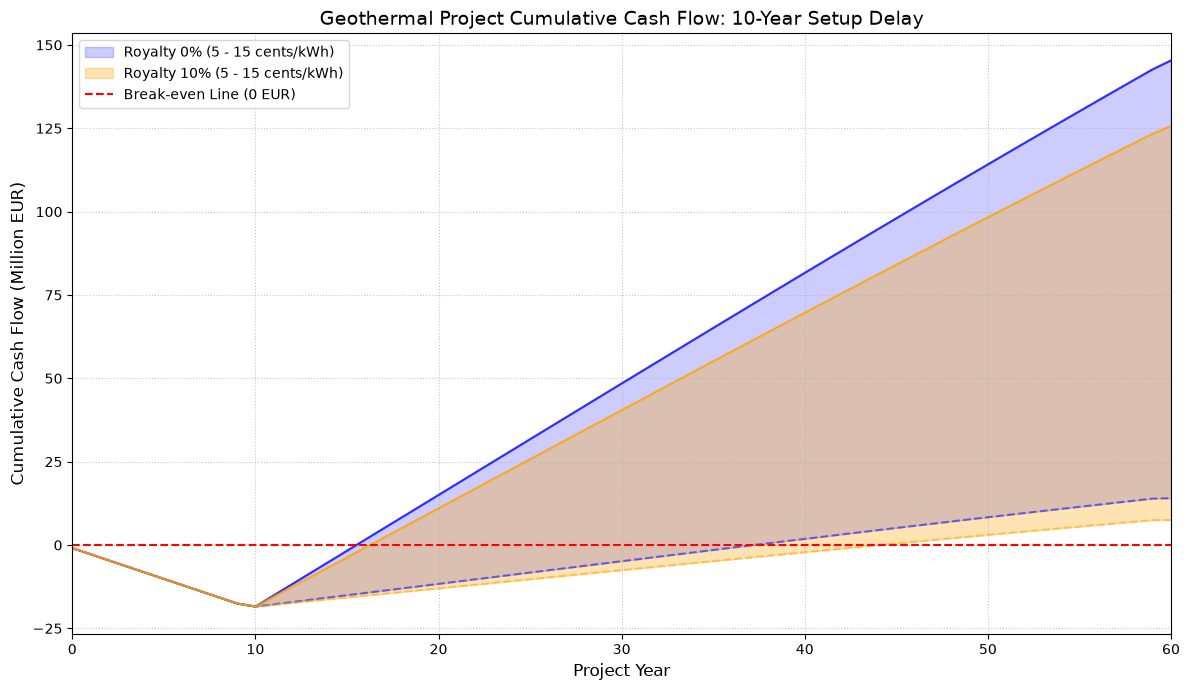

In [8]:
import numpy as np
import matplotlib.pyplot as plt

Measured_depth = 2500
Drilling_costs = 375000 + 1150 * Measured_depth + 0.3 * (Measured_depth)**2
Construction_costs = 0.5 * Drilling_costs
Site_preparation_costs = 0.1 * Drilling_costs
Equipment_costs = 0.2 * Drilling_costs 

Capex = Drilling_costs + Construction_costs + Site_preparation_costs + Equipment_costs
Opex = 0.1 * Capex
Abex =  0.05 * Capex

# First 10 years of zero production, followed by 50 years of production (Total = 60 years)
prod_values = [
    35557.544870, 35556.931177, 35556.443997, 35556.130896, 35555.936123,
    35555.830991, 35555.789027, 35555.774310, 35555.728290, 35555.555029,
    35555.107284, 35554.176844, 35552.491811, 35549.721719, 35545.489931,
    35539.391389, 35531.013049, 35519.954437, 35505.846130, 35488.364675,
    35467.243227, 35442.277763, 35413.329232, 35380.322282, 35343.241318,
    35302.124697, 35257.057755, 35208.165314, 35155.604127, 35099.555650,
    35040.219354, 34977.806782, 34912.536365, 34844.629052, 34774.304724,
    34701.779306, 34627.262549, 34550.956363, 34473.053625, 34393.737418,
    34313.180582, 34231.545525, 34148.984257, 34065.638571, 33981.640339,
    33897.111902, 33812.166493, 33726.908720, 33641.435032, 33555.834215
]
MWh = [0] * 10 + prod_values
MWh_array = np.array(MWh)

# Function to calculate cash flows
def calculate_cash_flow(unit_price, royalty_rate):
    annual_cash_flows = np.zeros(61)
    
    # Spread CAPEX evenly across the first 10 years (Years 0 to 9)
    for year in range(10):
        annual_cash_flows[year] -= Capex / 10
        
    annual_depreciation = Capex / 60 

    for i, prod_MWh in enumerate(MWh_array):
        year = i + 1
        annual_revenue = prod_MWh * 1000 * unit_price
        royalties = annual_revenue * royalty_rate
        ebitda = annual_revenue - Opex - royalties
        income_before_tax = ebitda - annual_depreciation
        tax = max(0, income_before_tax * 0.25)
        net_cash_flow = ebitda - tax
        
        if year == 60:
            net_cash_flow -= Abex
            
        # Add operating cash flow; this preserves any CAPEX already subtracted for that year
        annual_cash_flows[year] += net_cash_flow
        
    return np.cumsum(annual_cash_flows)

cf_0_low = calculate_cash_flow(0.05, 0.0)
cf_0_high = calculate_cash_flow(0.15, 0.0)
cf_10_low = calculate_cash_flow(0.05, 0.10)
cf_10_high = calculate_cash_flow(0.15, 0.10)

plt.figure(figsize=(12, 7))
years = np.arange(0, 61)

# Royalty 0% range
plt.fill_between(years, cf_0_low / 1e6, cf_0_high / 1e6, color='blue', alpha=0.2, label='Royalty 0% (5 - 15 cents/kWh)')
plt.plot(years, cf_0_low / 1e6, color='blue', linestyle='--', alpha=0.5)
plt.plot(years, cf_0_high / 1e6, color='blue', linestyle='-', alpha=0.8)

# Royalty 10% range
plt.fill_between(years, cf_10_low / 1e6, cf_10_high / 1e6, color='orange', alpha=0.3, label='Royalty 10% (5 - 15 cents/kWh)')
plt.plot(years, cf_10_low / 1e6, color='orange', linestyle='--', alpha=0.5)
plt.plot(years, cf_10_high / 1e6, color='orange', linestyle='-', alpha=0.8)

plt.axhline(0, color='red', linestyle='--', label='Break-even Line (0 EUR)')
plt.title('Geothermal Project Cumulative Cash Flow: 10-Year Setup Delay', fontsize=14)
plt.xlabel('Project Year', fontsize=12)
plt.ylabel('Cumulative Cash Flow (Million EUR)', fontsize=12)
plt.xlim(0, 60)
plt.grid(True, linestyle=':', alpha=0.7)
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()